In [57]:
from pathlib import Path
import math
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import matplotlib.dates as mdates

In [44]:
percent_formatter = FuncFormatter(
    lambda value, position: f"{value:.1f}%"
)

## Logement et concentration

In [3]:
CONCENTRATIONS_FILE = Path("./outputs/household_concentrations.csv.gz")
EVENTS_FILES = [
    Path("./outputs/household_events.csv.gz"),
    Path("./outputs/household_events.csv"),
]

In [4]:
OUTPUT_DIR = Path("./figures/visualisations_logements")
OUTPUT_DIR.mkdir(exist_ok=True)

SCENARIO_ORDER = ["clean", "cooking", "tobacco", "biomass_extreme"]
DAY_TYPE_ORDER = ["semaine", "weekend"]

In [5]:
concentrations = pd.read_csv(
    CONCENTRATIONS_FILE,
    usecols=[
        "household_id",
        "date",
        "day_type",
        "slot_15min",
        "emission_scenario",
        "pm25_indoor",
    ],
)

concentrations["date"] = pd.to_datetime(concentrations["date"])
concentrations["slot_15min"] = pd.to_numeric(
    concentrations["slot_15min"], errors="coerce"
)
concentrations["pm25_indoor"] = pd.to_numeric(
    concentrations["pm25_indoor"], errors="coerce"
)

concentrations = concentrations.dropna(
    subset=[
        "household_id",
        "slot_15min",
        "emission_scenario",
        "pm25_indoor",
    ]
)

In [6]:
events_file = next((path for path in EVENTS_FILES if path.exists()), None)

if events_file is not None:
    events = pd.read_csv(events_file)
else:
    events = None

In [7]:
# ============================================================
# Fonctions utilitaires
# ============================================================

def format_hour_axis(ax):
    """Formate l'axe des 96 créneaux de 15 minutes en heures."""
    hour_ticks = np.arange(0, 97, 12)
    hour_labels = [f"{int(slot / 4):02d}h" for slot in hour_ticks]

    ax.set_xlim(0, 95)
    ax.set_xticks(hour_ticks[:-1])
    ax.set_xticklabels(hour_labels[:-1])
    ax.set_xlabel("Heure de la journée")


def ordered_values(series, preferred_order):
    """Conserve uniquement les modalités présentes."""
    present = set(series.dropna().unique())
    ordered = [value for value in preferred_order if value in present]
    remaining = sorted(present.difference(ordered))
    return ordered + remaining

#### Profil journalier moyen par logement

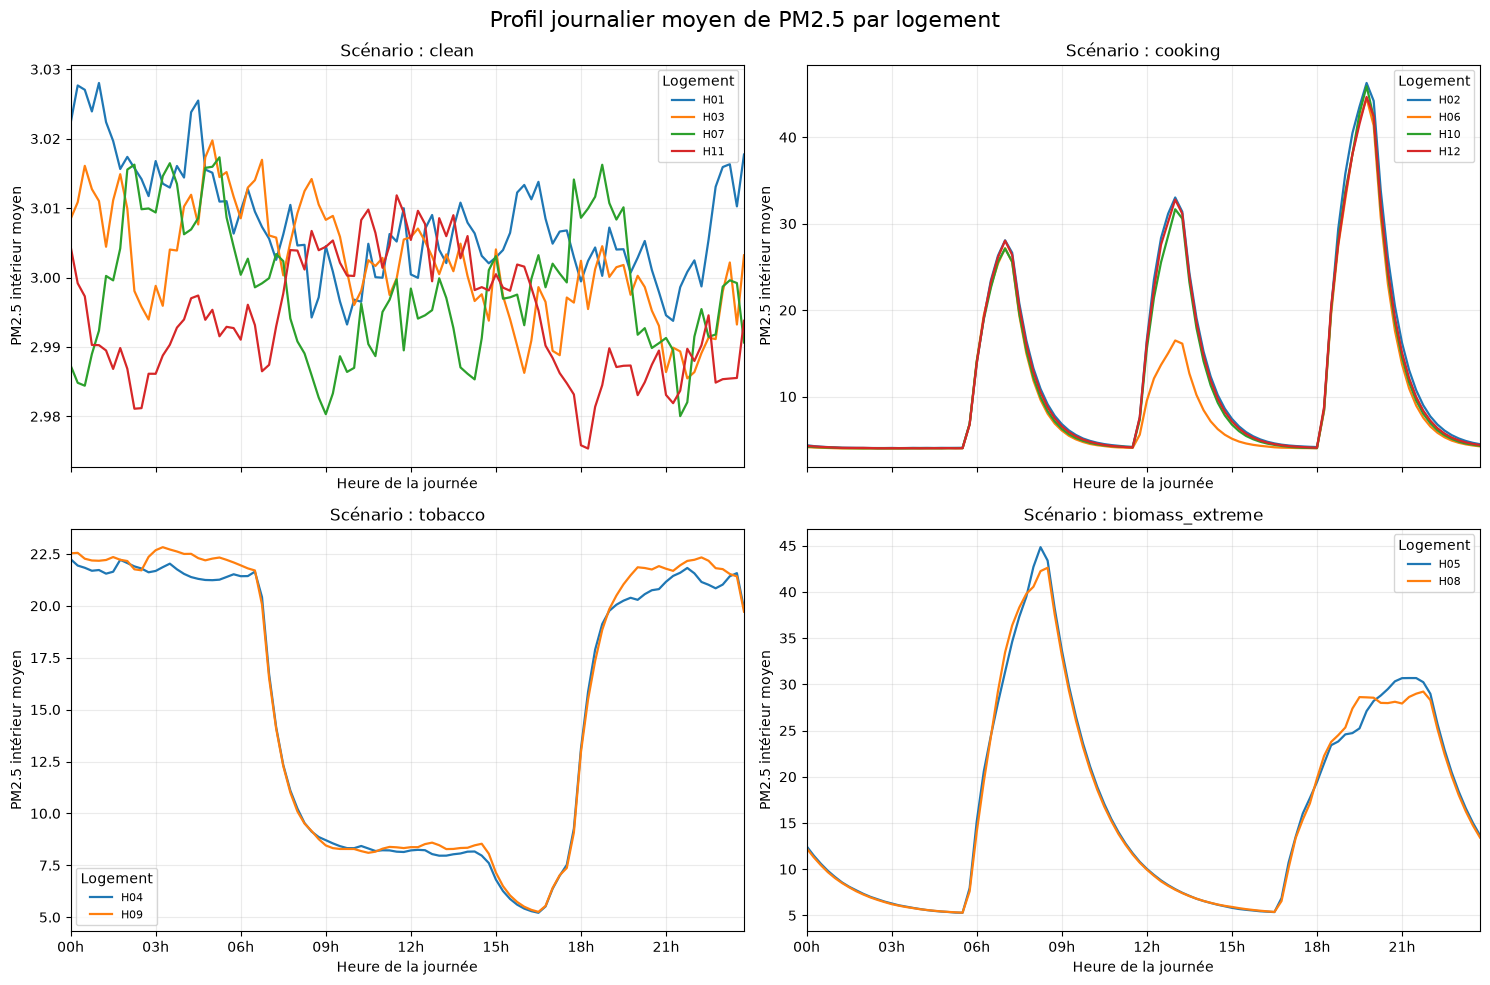

In [8]:
daily_profiles = (
    concentrations
    .groupby(
        ["emission_scenario", "household_id", "slot_15min"],
        as_index=False,
    )["pm25_indoor"]
    .mean()
)

scenarios = ordered_values(
    daily_profiles["emission_scenario"],
    SCENARIO_ORDER,
)

ncols = 2
nrows = math.ceil(len(scenarios) / ncols)

fig, axes = plt.subplots(
    nrows=nrows,
    ncols=ncols,
    figsize=(15, 5 * nrows),
    sharex=True,
    squeeze=False,
)

for ax, scenario in zip(axes.flat, scenarios):
    scenario_data = daily_profiles[
        daily_profiles["emission_scenario"] == scenario
    ]

    for household_id, household_data in scenario_data.groupby("household_id"):
        household_data = household_data.sort_values("slot_15min")

        ax.plot(
            household_data["slot_15min"],
            household_data["pm25_indoor"],
            linewidth=1.6,
            label=household_id,
        )

    ax.set_title(f"Scénario : {scenario}")
    ax.set_ylabel("PM2.5 intérieur moyen")
    ax.legend(title="Logement", fontsize=8)
    ax.grid(alpha=0.25)
    format_hour_axis(ax)

for ax in axes.flat[len(scenarios):]:
    ax.set_visible(False)

fig.suptitle(
    "Profil journalier moyen de PM2.5 par logement",
    fontsize=16,
)
fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "1_1_profils_journaliers_par_logement.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()


#### Distribution des concentrations par scénario

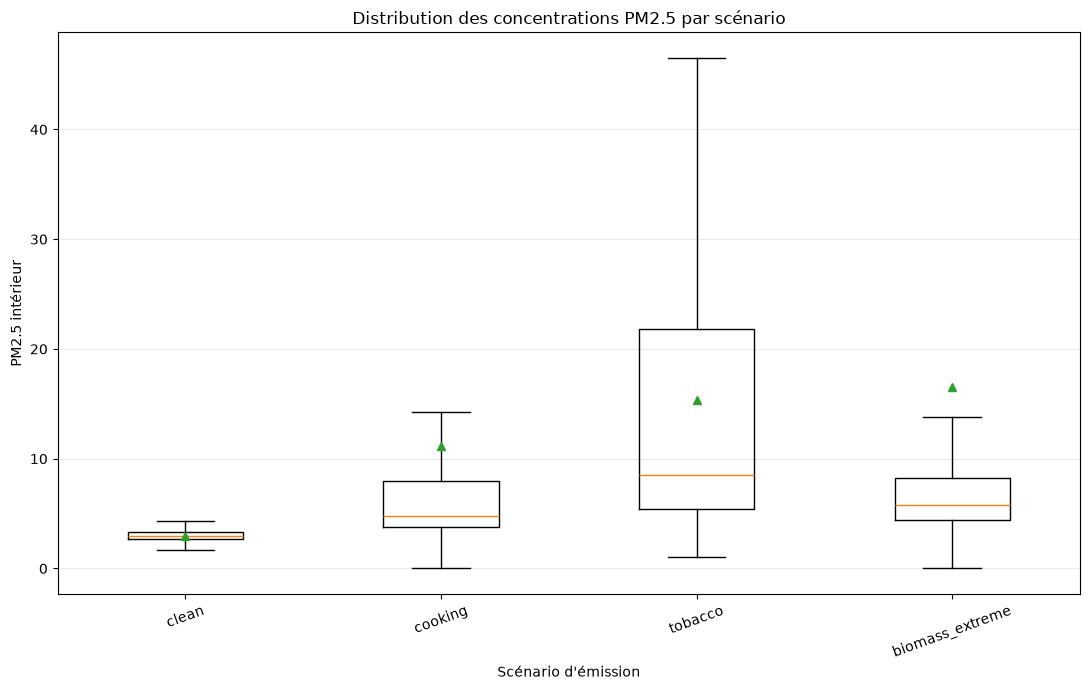

In [16]:
scenarios = ordered_values(
    concentrations["emission_scenario"],
    SCENARIO_ORDER,
)

boxplot_data = [
    concentrations.loc[
        concentrations["emission_scenario"] == scenario,
        "pm25_indoor",
    ].dropna().to_numpy()
    for scenario in scenarios
]

fig, ax = plt.subplots(figsize=(11, 7))

ax.boxplot(
    boxplot_data,
    tick_labels=scenarios,
    showfliers=False,
    showmeans=True,
)

ax.set_title("Distribution des concentrations PM2.5 par scénario")
ax.set_xlabel("Scénario d'émission")
ax.set_ylabel("PM2.5 intérieur")
ax.tick_params(axis="x", rotation=20)
ax.grid(axis="y", alpha=0.25)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "1_2_distribution_pm25_par_scenario.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

#### Fréquence et amplitude des événements domestiques

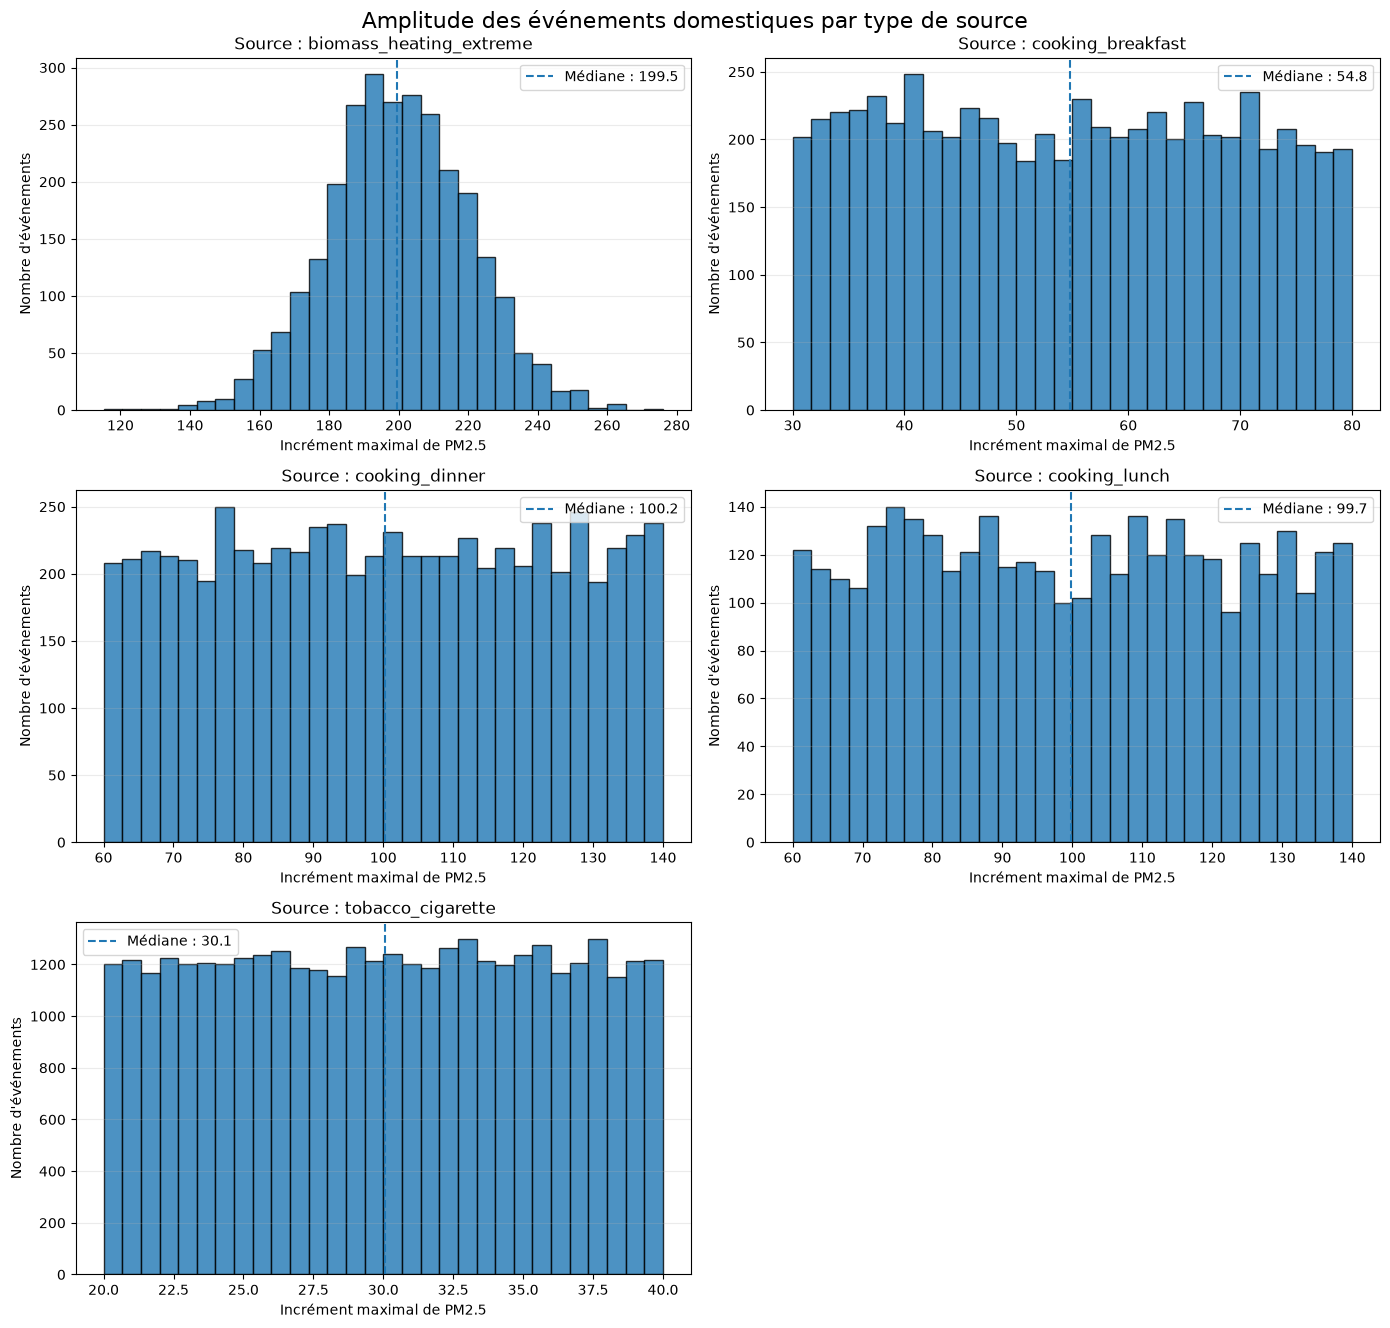

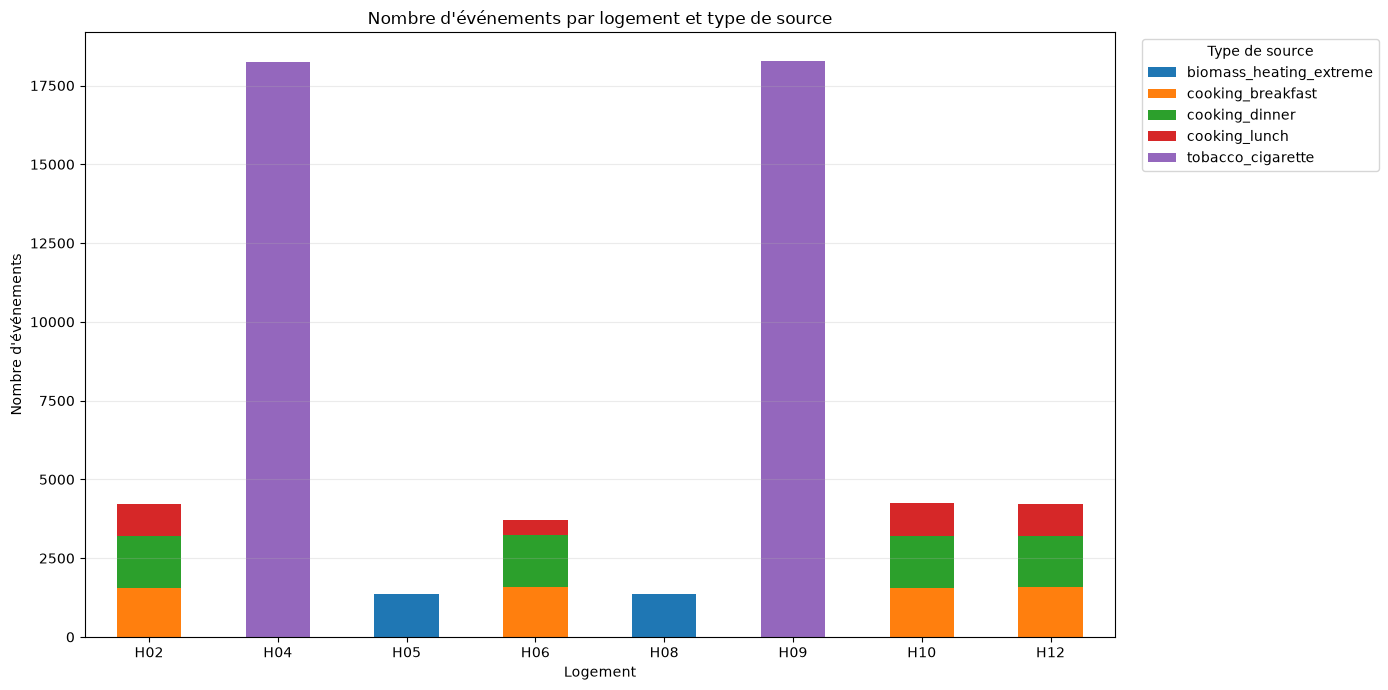

In [12]:
if events is not None:
    required_columns = {
        "household_id",
        "source_type",
        "peak_increment_pm25",
    }

    missing_columns = required_columns.difference(events.columns)

    if missing_columns:
        raise ValueError(
            "Colonnes manquantes dans household_events.csv : "
            + ", ".join(sorted(missing_columns))
        )

    events["peak_increment_pm25"] = pd.to_numeric(
        events["peak_increment_pm25"],
        errors="coerce",
    )

    events = events.dropna(
        subset=[
            "household_id",
            "source_type",
            "peak_increment_pm25",
        ]
    )

    source_types = sorted(events["source_type"].unique())

    # --------------------------------------------------------
    # 1.3a — Histogrammes de l'amplitude par type de source
    # --------------------------------------------------------

    ncols = 2
    nrows = math.ceil(len(source_types) / ncols)

    fig, axes = plt.subplots(
        nrows=nrows,
        ncols=ncols,
        figsize=(14, 4.5 * nrows),
        squeeze=False,
    )

    for ax, source_type in zip(axes.flat, source_types):
        values = events.loc[
            events["source_type"] == source_type,
            "peak_increment_pm25",
        ]

        ax.hist(values, bins=30, edgecolor="black", alpha=0.8)
        ax.axvline(
            values.median(),
            linestyle="--",
            linewidth=1.5,
            label=f"Médiane : {values.median():.1f}",
        )

        ax.set_title(f"Source : {source_type}")
        ax.set_xlabel("Incrément maximal de PM2.5")
        ax.set_ylabel("Nombre d'événements")
        ax.legend()
        ax.grid(axis="y", alpha=0.25)

    for ax in axes.flat[len(source_types):]:
        ax.set_visible(False)

    fig.suptitle(
        "Amplitude des événements domestiques par type de source",
        fontsize=16,
    )
    fig.tight_layout()

    fig.savefig(
        OUTPUT_DIR / "1_3a_amplitude_evenements_par_source.png",
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()

    # --------------------------------------------------------
    # 1.3b — Nombre d'événements par logement et type
    # --------------------------------------------------------

    event_counts = (
        events
        .groupby(["household_id", "source_type"])
        .size()
        .unstack(fill_value=0)
        .sort_index()
    )

    fig, ax = plt.subplots(figsize=(14, 7))

    event_counts.plot(
        kind="bar",
        stacked=True,
        ax=ax,
    )

    ax.set_title("Nombre d'événements par logement et type de source")
    ax.set_xlabel("Logement")
    ax.set_ylabel("Nombre d'événements")
    ax.tick_params(axis="x", rotation=0)
    ax.legend(
        title="Type de source",
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
    )
    ax.grid(axis="y", alpha=0.25)

    fig.tight_layout()

    fig.savefig(
        OUTPUT_DIR / "1_3b_nombre_evenements_par_logement.png",
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()

else:
    print(
        "Visualisation 1.3 ignorée : "
        "household_events.csv ou household_events.csv.gz introuvable."
    )


#### Comparaison semaine / week-end

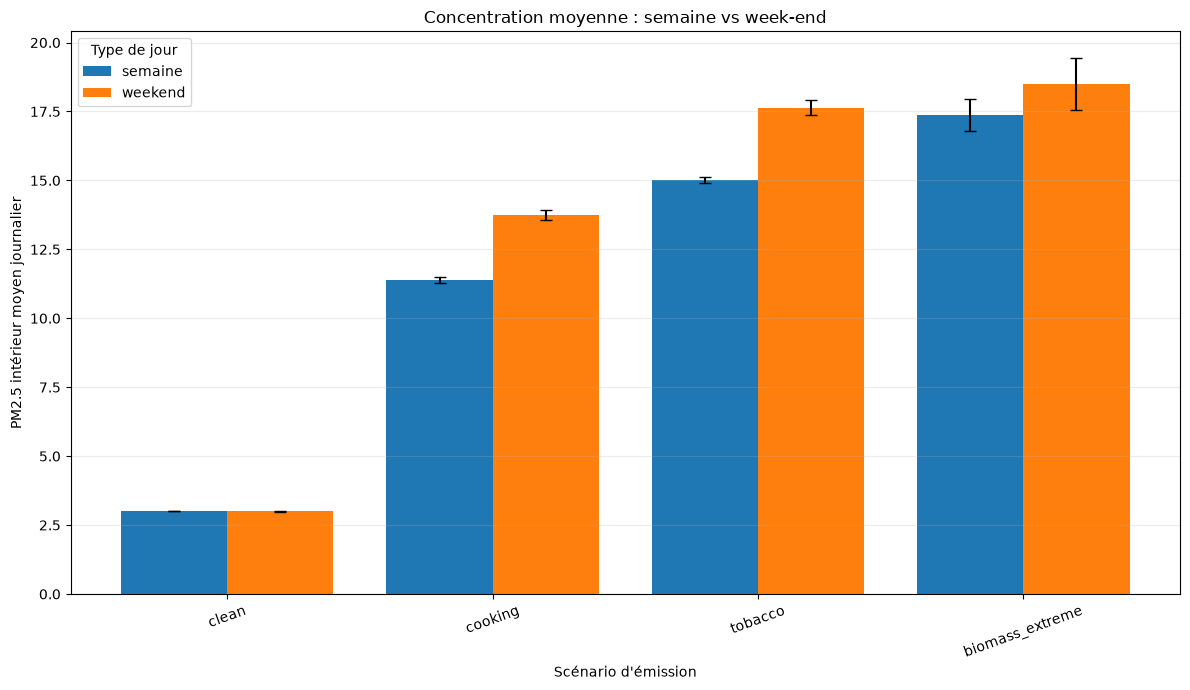

In [13]:
# Moyenne quotidienne par logement afin que chaque journée ait le même poids.
daily_household_mean = (
    concentrations
    .groupby(
        [
            "date",
            "household_id",
            "emission_scenario",
            "day_type",
        ],
        as_index=False,
    )["pm25_indoor"]
    .mean()
    .rename(columns={"pm25_indoor": "daily_mean_pm25"})
)

comparison = (
    daily_household_mean
    .groupby(
        ["emission_scenario", "day_type"]
    )["daily_mean_pm25"]
    .agg(["mean", "std", "count"])
    .reset_index()
)

comparison["sem"] = comparison["std"] / np.sqrt(comparison["count"])
comparison["ci95"] = 1.96 * comparison["sem"]

scenarios = ordered_values(
    comparison["emission_scenario"],
    SCENARIO_ORDER,
)

day_types = ordered_values(
    comparison["day_type"],
    DAY_TYPE_ORDER,
)

x = np.arange(len(scenarios))
width = 0.8 / max(len(day_types), 1)

fig, ax = plt.subplots(figsize=(12, 7))

for index, day_type in enumerate(day_types):
    subset = (
        comparison[comparison["day_type"] == day_type]
        .set_index("emission_scenario")
        .reindex(scenarios)
    )

    positions = x - 0.4 + width / 2 + index * width

    ax.bar(
        positions,
        subset["mean"],
        width=width,
        yerr=subset["ci95"],
        capsize=4,
        label=day_type,
    )

ax.set_title("Concentration moyenne : semaine vs week-end")
ax.set_xlabel("Scénario d'émission")
ax.set_ylabel("PM2.5 intérieur moyen journalier")
ax.set_xticks(x)
ax.set_xticklabels(scenarios, rotation=20)
ax.legend(title="Type de jour")
ax.grid(axis="y", alpha=0.25)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "1_4_semaine_vs_weekend.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

## Personas et population

In [19]:
INDIVIDUALS_FILE = Path("./config/individuals.csv")
HEALTH_FILE = Path("./outputs/initial_health_states.csv")

OUTPUT_DIR_PERSONA = Path("./figures/visualisations_personas")
OUTPUT_DIR_PERSONA.mkdir(exist_ok=True)

PERSONA_ORDER = ["P1", "P2", "P3", "P4", "P5"]
SCENARIO_ORDER = ["clean", "cooking", "tobacco", "biomass_extreme"]

In [26]:
individuals = pd.read_csv(INDIVIDUALS_FILE)
health = pd.read_csv(HEALTH_FILE)

individuals["age_at_start"] = pd.to_numeric(
    individuals["age_at_start"],
    errors="coerce",
)

# Une seule ligne par logement est nécessaire pour connaître son scénario.
household_scenarios = (
    pd.read_csv(
        CONCENTRATIONS_FILE,
        usecols=["household_id", "emission_scenario"],
    )
    .drop_duplicates()
)

# Vérification : un logement doit avoir un seul scénario.
scenario_count = (
    household_scenarios
    .groupby("household_id")["emission_scenario"]
    .nunique()
)

if scenario_count.max() > 1:
    raise ValueError(
        "Au moins un logement possède plusieurs scénarios d'émission."
    )

health_personas = health.merge(
    individuals[
        [
            "individual_id",
            "persona_id",
            "sex",
            "age_at_start",
            "household_id",
        ]
    ],
    on="individual_id",
    how="left",
    validate="one_to_one",
)

#### Tableau démographique de la cohorte

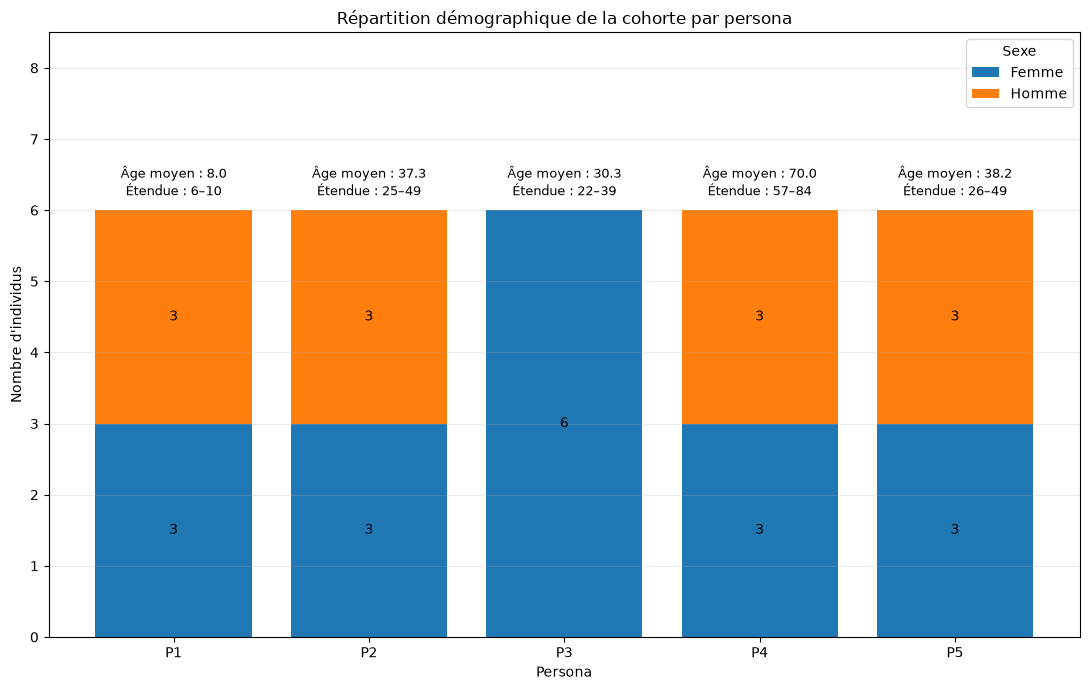

In [28]:
demographic_table = (
    individuals[
        [
            "individual_id",
            "persona_id",
            "age_at_start",
            "sex",
            "household_id",
        ]
    ]
    .sort_values(
        ["persona_id", "age_at_start", "individual_id"]
    )
    .reset_index(drop=True)
)

# Sauvegarde du tableau détaillé.
demographic_table.to_csv(
    OUTPUT_DIR_PERSONA / "2_1_tableau_demographique.csv",
    index=False,
)

# Résumé par persona et sexe.
persona_sex_counts = (
    individuals
    .groupby(["persona_id", "sex"])
    .size()
    .unstack(fill_value=0)
    .reindex(PERSONA_ORDER, fill_value=0)
)

age_summary = (
    individuals
    .groupby("persona_id")["age_at_start"]
    .agg(
        effectif="count",
        age_moyen="mean",
        age_min="min",
        age_max="max",
    )
    .reindex(PERSONA_ORDER)
)

fig, ax = plt.subplots(figsize=(11, 7))

bottom = np.zeros(len(persona_sex_counts))

for sex in persona_sex_counts.columns:
    values = persona_sex_counts[sex].to_numpy()

    bars = ax.bar(
        persona_sex_counts.index,
        values,
        bottom=bottom,
        label=sex,
    )

    ax.bar_label(
        bars,
        labels=[
            str(int(value)) if value > 0 else ""
            for value in values
        ],
        label_type="center",
    )

    bottom += values

# Ajouter les informations d'âge au-dessus de chaque barre.
for index, persona in enumerate(persona_sex_counts.index):
    row = age_summary.loc[persona]

    label = (
        f"Âge moyen : {row['age_moyen']:.1f}\n"
        f"Étendue : {row['age_min']:.0f}–{row['age_max']:.0f}"
    )

    ax.text(
        index,
        row["effectif"] + 0.15,
        label,
        ha="center",
        va="bottom",
        fontsize=9,
    )

ax.set_title("Répartition démographique de la cohorte par persona")
ax.set_xlabel("Persona")
ax.set_ylabel("Nombre d'individus")
ax.set_ylim(
    0,
    age_summary["effectif"].max() + 2.5,
)
ax.legend(title="Sexe")
ax.grid(axis="y", alpha=0.25)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR_PERSONA / "2_1_repartition_demographique.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

#### Tableau graphique détaillé

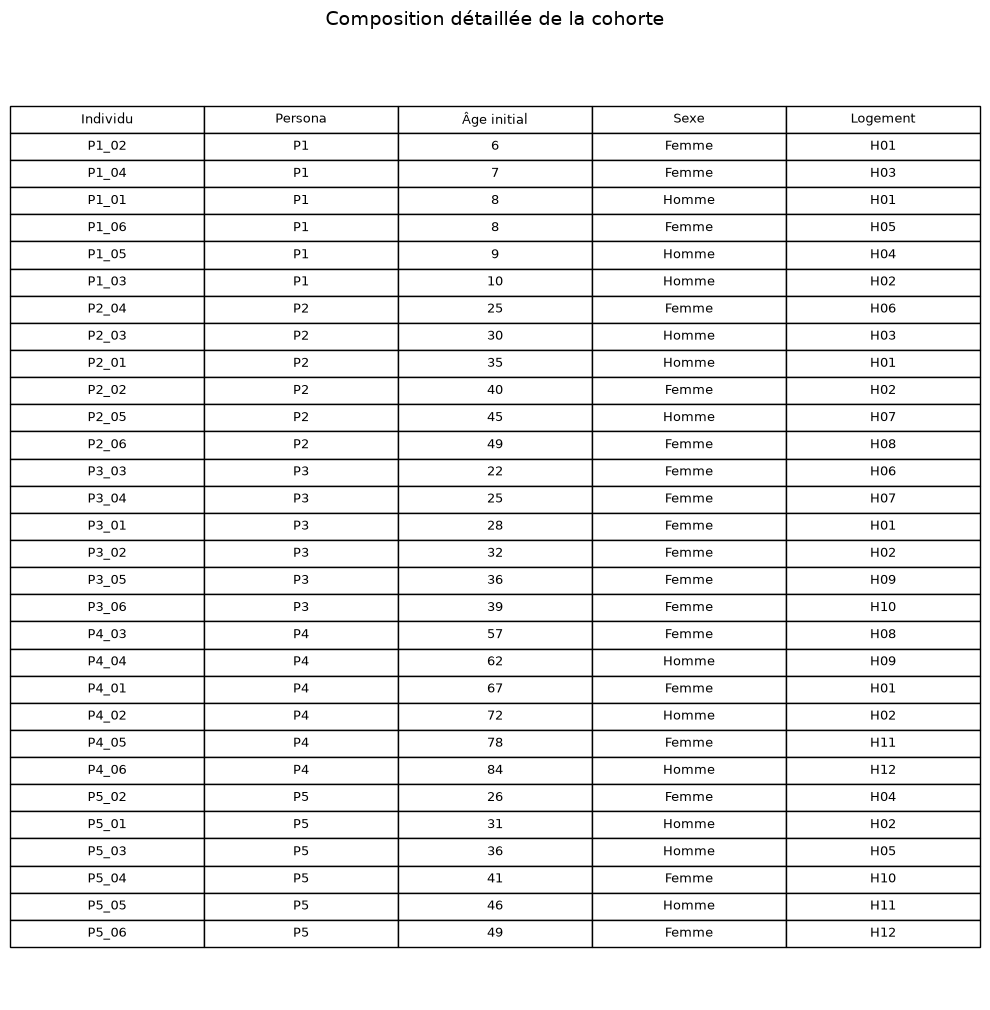

In [29]:
display_table = demographic_table.copy()

display_table.columns = [
    "Individu",
    "Persona",
    "Âge initial",
    "Sexe",
    "Logement",
]

fig_height = max(8, len(display_table) * 0.34)

fig, ax = plt.subplots(
    figsize=(10, fig_height)
)

ax.axis("off")

table = ax.table(
    cellText=display_table.values,
    colLabels=display_table.columns,
    cellLoc="center",
    colLoc="center",
    loc="center",
)

table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1, 1.35)

ax.set_title(
    "Composition détaillée de la cohorte",
    fontsize=14,
    pad=20,
)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR_PERSONA / "2_1_tableau_demographique.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

#### Répartition des personas par scénario de logement

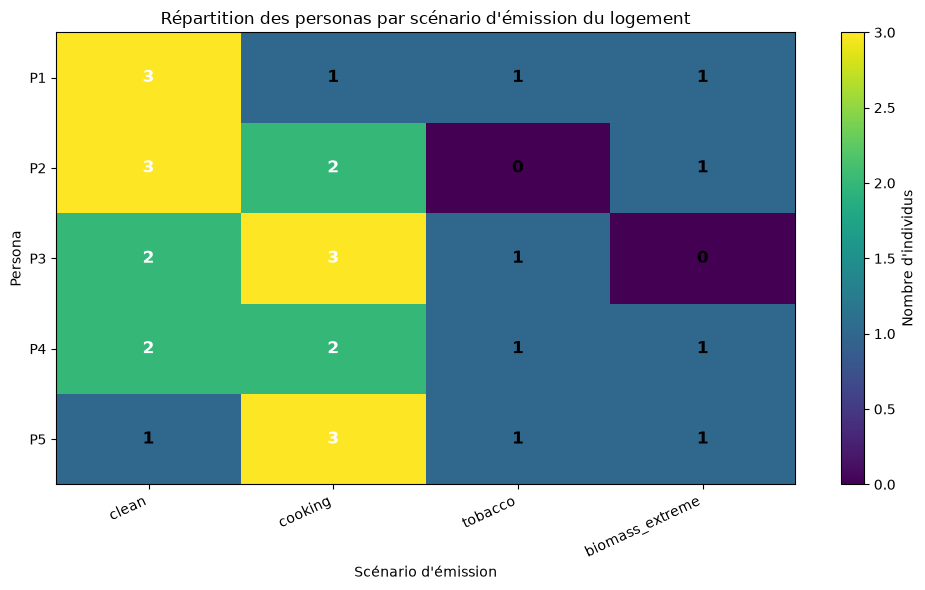

In [30]:
individuals_scenarios = individuals.merge(
    household_scenarios,
    on="household_id",
    how="left",
    validate="many_to_one",
)

if individuals_scenarios["emission_scenario"].isna().any():
    missing_households = (
        individuals_scenarios.loc[
            individuals_scenarios["emission_scenario"].isna(),
            "household_id",
        ]
        .drop_duplicates()
        .tolist()
    )

    raise ValueError(
        "Scénario absent pour les logements : "
        + ", ".join(map(str, missing_households))
    )

persona_scenario_table = pd.crosstab(
    individuals_scenarios["persona_id"],
    individuals_scenarios["emission_scenario"],
)

persona_scenario_table = persona_scenario_table.reindex(
    index=PERSONA_ORDER,
    columns=SCENARIO_ORDER,
    fill_value=0,
)

persona_scenario_table.to_csv(
    OUTPUT_DIR_PERSONA / "2_2_persona_par_scenario.csv"
)

fig, ax = plt.subplots(figsize=(10, 6))

image = ax.imshow(
    persona_scenario_table.to_numpy(),
    aspect="auto",
)

ax.set_xticks(
    np.arange(len(persona_scenario_table.columns))
)
ax.set_xticklabels(
    persona_scenario_table.columns,
    rotation=25,
    ha="right",
)

ax.set_yticks(
    np.arange(len(persona_scenario_table.index))
)
ax.set_yticklabels(
    persona_scenario_table.index
)

# Valeurs dans les cellules.
threshold = (
    persona_scenario_table.to_numpy().max() / 2
    if persona_scenario_table.to_numpy().max() > 0
    else 0
)

for row_index in range(persona_scenario_table.shape[0]):
    for column_index in range(persona_scenario_table.shape[1]):
        value = persona_scenario_table.iloc[
            row_index,
            column_index,
        ]

        ax.text(
            column_index,
            row_index,
            str(value),
            ha="center",
            va="center",
            color="white" if value > threshold else "black",
            fontsize=12,
            fontweight="bold",
        )

colorbar = fig.colorbar(image, ax=ax)
colorbar.set_label("Nombre d'individus")

ax.set_title(
    "Répartition des personas par scénario d'émission du logement"
)
ax.set_xlabel("Scénario d'émission")
ax.set_ylabel("Persona")

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR_PERSONA / "2_2_heatmap_persona_scenario.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

#### Répartition en pourcentage dans chaque persona

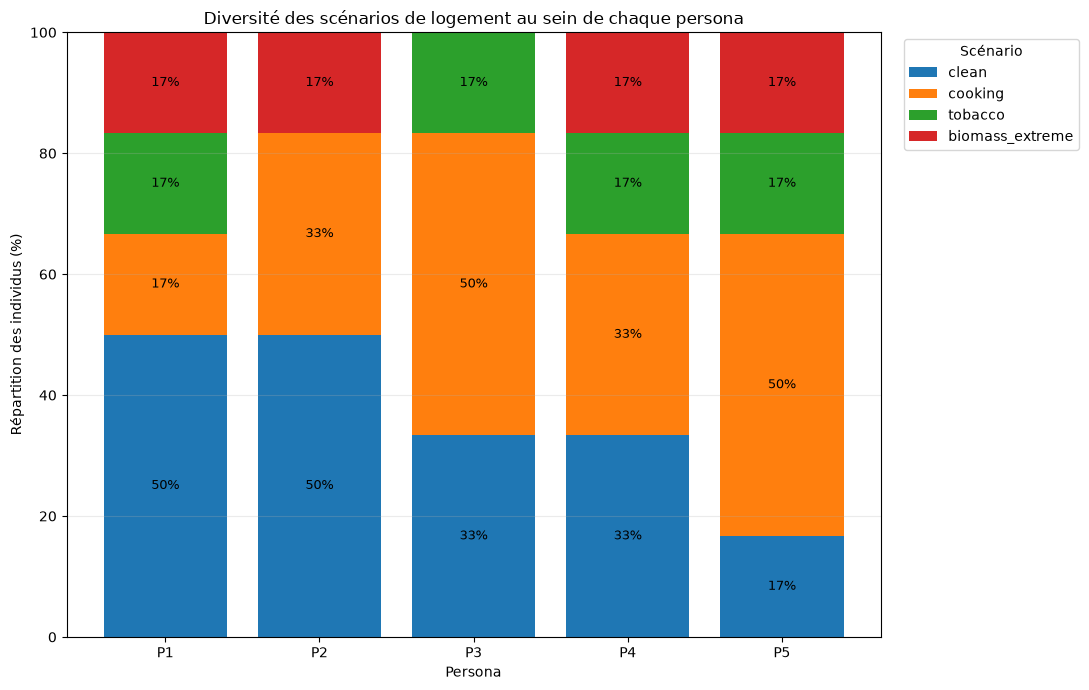

In [31]:
persona_scenario_percent = (
    persona_scenario_table
    .div(persona_scenario_table.sum(axis=1), axis=0)
    .mul(100)
)

fig, ax = plt.subplots(figsize=(11, 7))

bottom = np.zeros(len(persona_scenario_percent))

for scenario in persona_scenario_percent.columns:
    values = persona_scenario_percent[scenario].to_numpy()

    bars = ax.bar(
        persona_scenario_percent.index,
        values,
        bottom=bottom,
        label=scenario,
    )

    labels = [
        f"{value:.0f}%" if value >= 5 else ""
        for value in values
    ]

    ax.bar_label(
        bars,
        labels=labels,
        label_type="center",
        fontsize=9,
    )

    bottom += values

ax.set_title(
    "Diversité des scénarios de logement au sein de chaque persona"
)
ax.set_xlabel("Persona")
ax.set_ylabel("Répartition des individus (%)")
ax.set_ylim(0, 100)

ax.legend(
    title="Scénario",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
)

ax.grid(axis="y", alpha=0.25)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR_PERSONA / "2_2_repartition_scenarios_pourcentage.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()


#### États de santé initiaux par persona

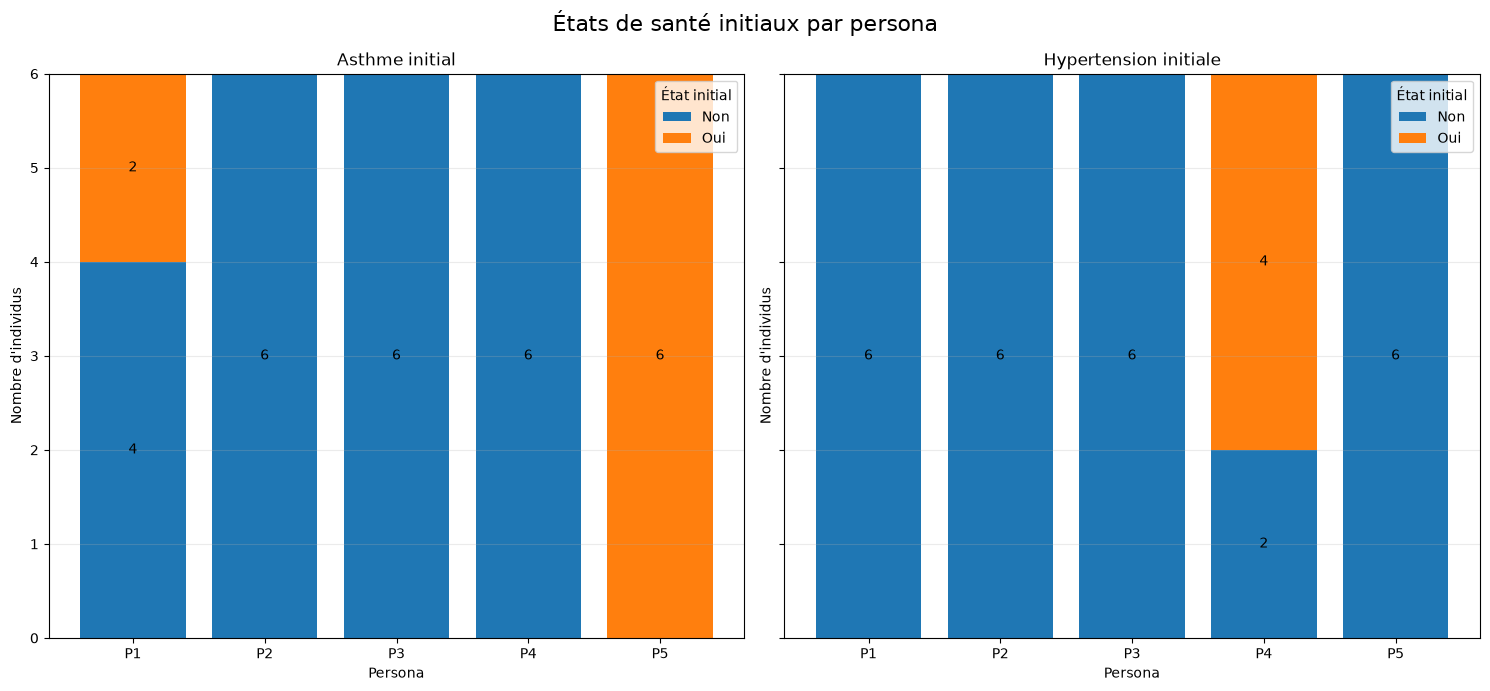

In [32]:
health_variables = {
    "baseline_asthma": "Asthme initial",
    "baseline_hypertension": "Hypertension initiale",
}

fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(15, 7),
    sharey=True,
)

for ax, (variable, title) in zip(
    axes,
    health_variables.items(),
):
    health_personas[variable] = pd.to_numeric(
        health_personas[variable],
        errors="coerce",
    )

    counts = (
        health_personas
        .groupby(["persona_id", variable])
        .size()
        .unstack(fill_value=0)
        .reindex(
            index=PERSONA_ORDER,
            columns=[0, 1],
            fill_value=0,
        )
    )

    counts.columns = ["Non", "Oui"]

    bottom = np.zeros(len(counts))

    for status in ["Non", "Oui"]:
        values = counts[status].to_numpy()

        bars = ax.bar(
            counts.index,
            values,
            bottom=bottom,
            label=status,
        )

        ax.bar_label(
            bars,
            labels=[
                str(int(value)) if value > 0 else ""
                for value in values
            ],
            label_type="center",
        )

        bottom += values

    ax.set_title(title)
    ax.set_xlabel("Persona")
    ax.set_ylabel("Nombre d'individus")
    ax.grid(axis="y", alpha=0.25)
    ax.legend(title="État initial")

fig.suptitle(
    "États de santé initiaux par persona",
    fontsize=16,
)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR_PERSONA / "2_3_etats_sante_initiaux.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

#### Taux initiaux par persona

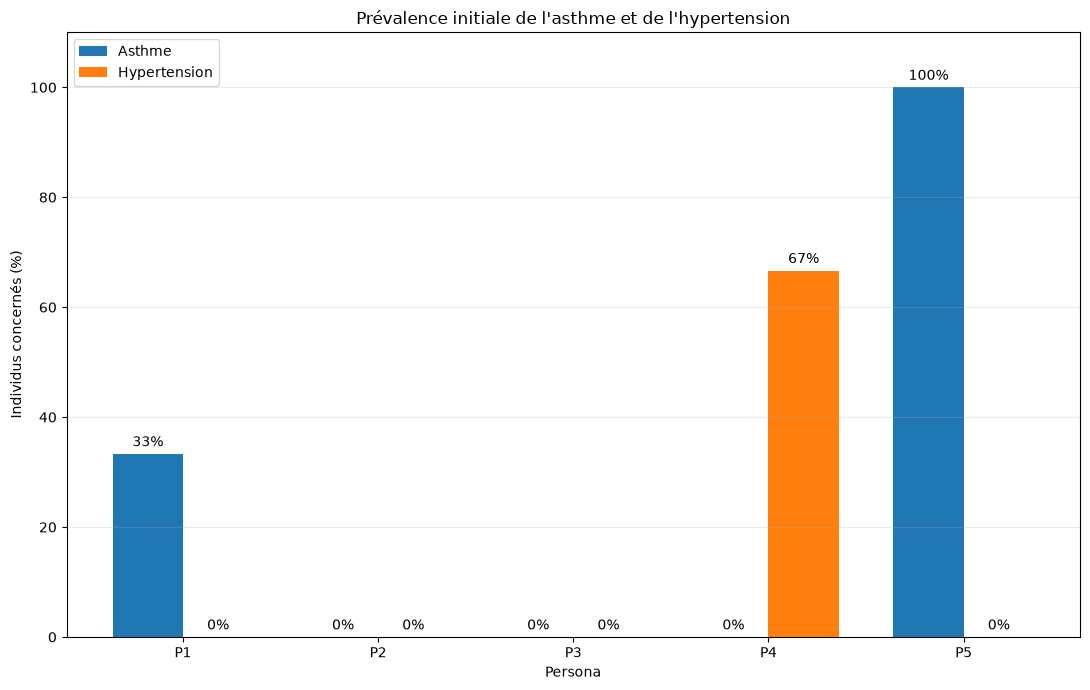

In [33]:
health_rates = (
    health_personas
    .groupby("persona_id")[
        ["baseline_asthma", "baseline_hypertension"]
    ]
    .mean()
    .mul(100)
    .reindex(PERSONA_ORDER)
    .rename(
        columns={
            "baseline_asthma": "Asthme",
            "baseline_hypertension": "Hypertension",
        }
    )
)

x = np.arange(len(health_rates))
width = 0.36

fig, ax = plt.subplots(figsize=(11, 7))

asthma_bars = ax.bar(
    x - width / 2,
    health_rates["Asthme"],
    width,
    label="Asthme",
)

hypertension_bars = ax.bar(
    x + width / 2,
    health_rates["Hypertension"],
    width,
    label="Hypertension",
)

ax.bar_label(
    asthma_bars,
    fmt="%.0f%%",
    padding=3,
)

ax.bar_label(
    hypertension_bars,
    fmt="%.0f%%",
    padding=3,
)

ax.set_title(
    "Prévalence initiale de l'asthme et de l'hypertension"
)
ax.set_xlabel("Persona")
ax.set_ylabel("Individus concernés (%)")
ax.set_xticks(x)
ax.set_xticklabels(health_rates.index)
ax.set_ylim(
    0,
    max(100, health_rates.to_numpy().max() + 10),
)
ax.legend()
ax.grid(axis="y", alpha=0.25)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "2_3_taux_sante_initiaux.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

## Risque de base p0

In [34]:
P0_FILE = Path("./outputs/individual_p0_schedule.csv")

OUTPUT_DIR_P0 = Path("./figures/visualisations_p0")
OUTPUT_DIR_P0.mkdir(exist_ok=True)

PERSONA_ORDER = ["P1", "P2", "P3", "P4", "P5"]
EVENT_ORDER = ["E02", "E03", "E04", "E05", "E08"]

In [35]:
p0 = pd.read_csv(P0_FILE)

required_columns = {
    "individual_id",
    "persona_id",
    "calendar_year",
    "age",
    "event_id",
    "event_name",
    "p0_value",
}

missing_columns = required_columns.difference(p0.columns)

if missing_columns:
    raise ValueError(
        "Colonnes manquantes : "
        + ", ".join(sorted(missing_columns))
    )

p0["calendar_year"] = pd.to_numeric(
    p0["calendar_year"],
    errors="coerce",
)

p0["age"] = pd.to_numeric(
    p0["age"],
    errors="coerce",
)

p0["p0_value"] = pd.to_numeric(
    p0["p0_value"],
    errors="coerce",
)

p0 = p0.dropna(
    subset=[
        "individual_id",
        "persona_id",
        "calendar_year",
        "event_id",
        "p0_value",
    ]
)

p0["calendar_year"] = p0["calendar_year"].astype(int)

event_order = [
    event_id
    for event_id in EVENT_ORDER
    if event_id in p0["event_id"].unique()
]

event_names = (
    p0[["event_id", "event_name"]]
    .drop_duplicates("event_id")
    .set_index("event_id")["event_name"]
    .to_dict()
)

#### Sélection d'un individu représentatif par persona

In [36]:
# L'individu retenu est celui possédant le plus grand nombre
# de couples événement × année dans son persona.
individual_coverage = (
    p0
    .drop_duplicates(
        [
            "persona_id",
            "individual_id",
            "event_id",
            "calendar_year",
        ]
    )
    .groupby(
        ["persona_id", "individual_id"]
    )
    .size()
    .rename("coverage")
    .reset_index()
)

representatives = (
    individual_coverage
    .sort_values(
        ["persona_id", "coverage", "individual_id"],
        ascending=[True, False, True],
    )
    .drop_duplicates("persona_id")
    .set_index("persona_id")["individual_id"]
    .to_dict()
)

print("Individus représentatifs sélectionnés :")
for persona in PERSONA_ORDER:
    if persona in representatives:
        print(f"{persona} : {representatives[persona]}")

Individus représentatifs sélectionnés :
P1 : P1_02
P2 : P2_01
P3 : P3_01
P4 : P4_01
P5 : P5_01


#### Évolution du p0 dans le temps

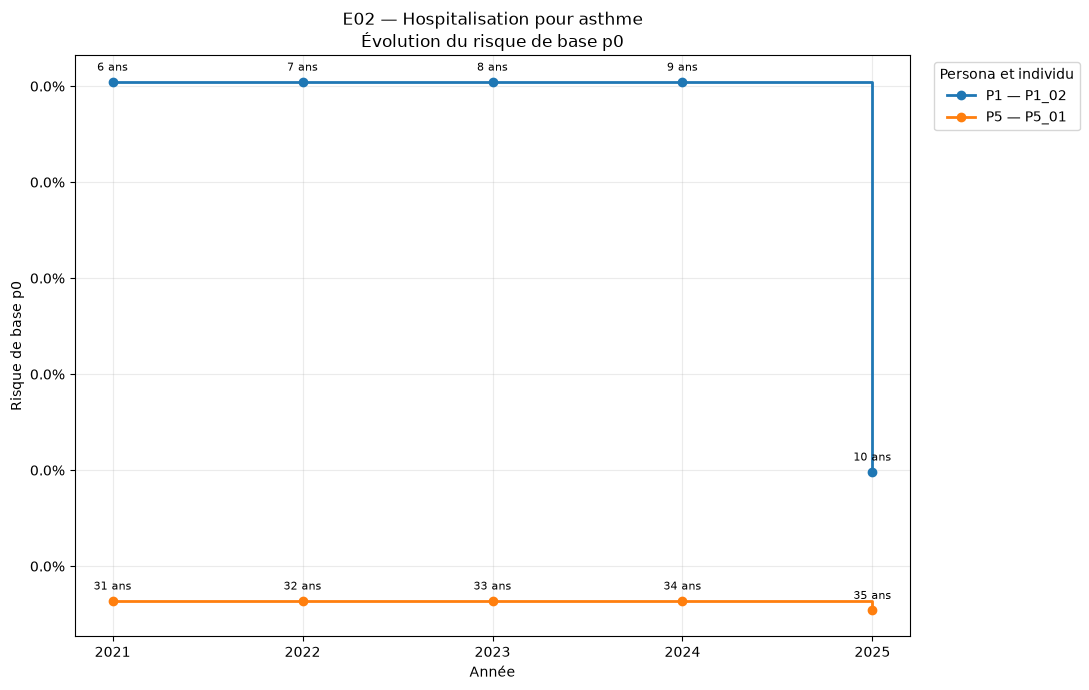

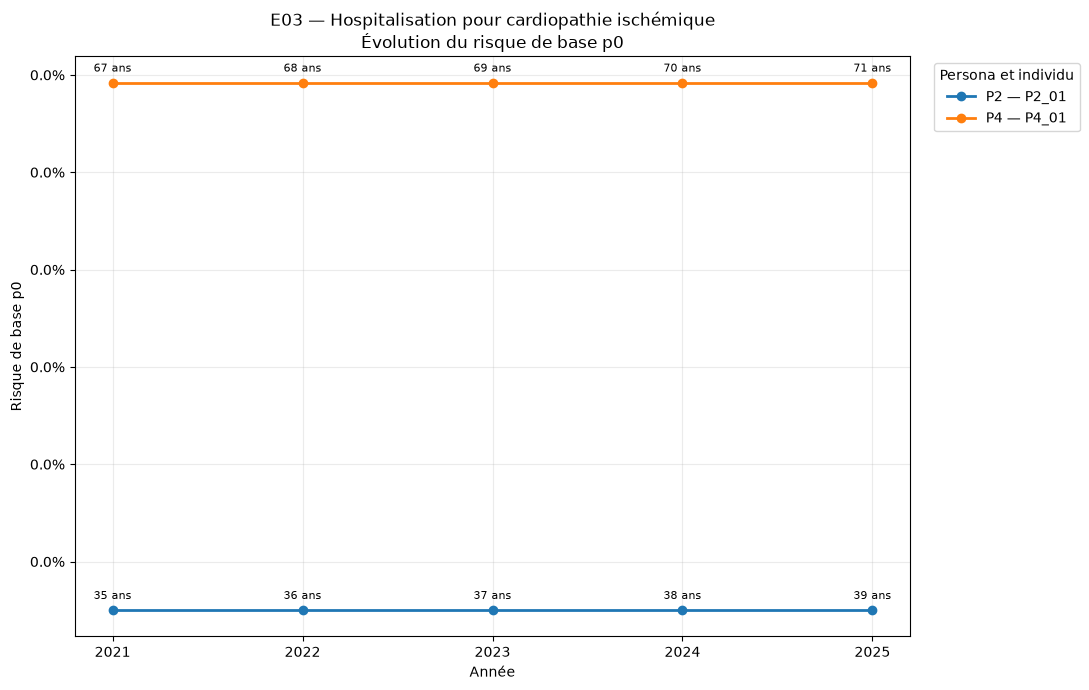

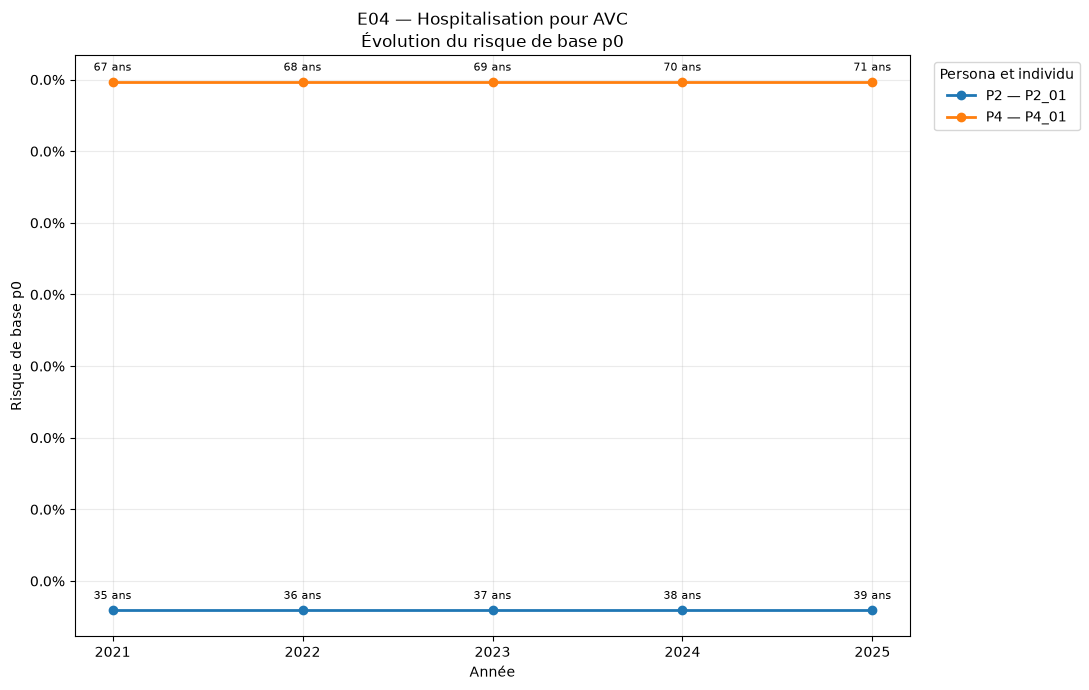

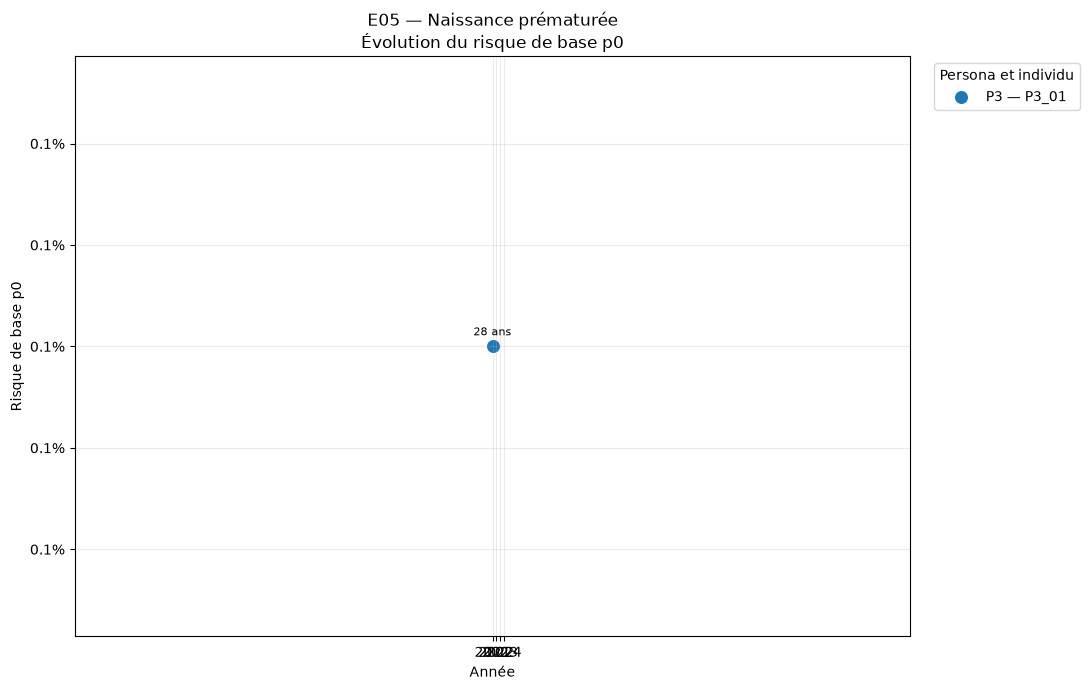

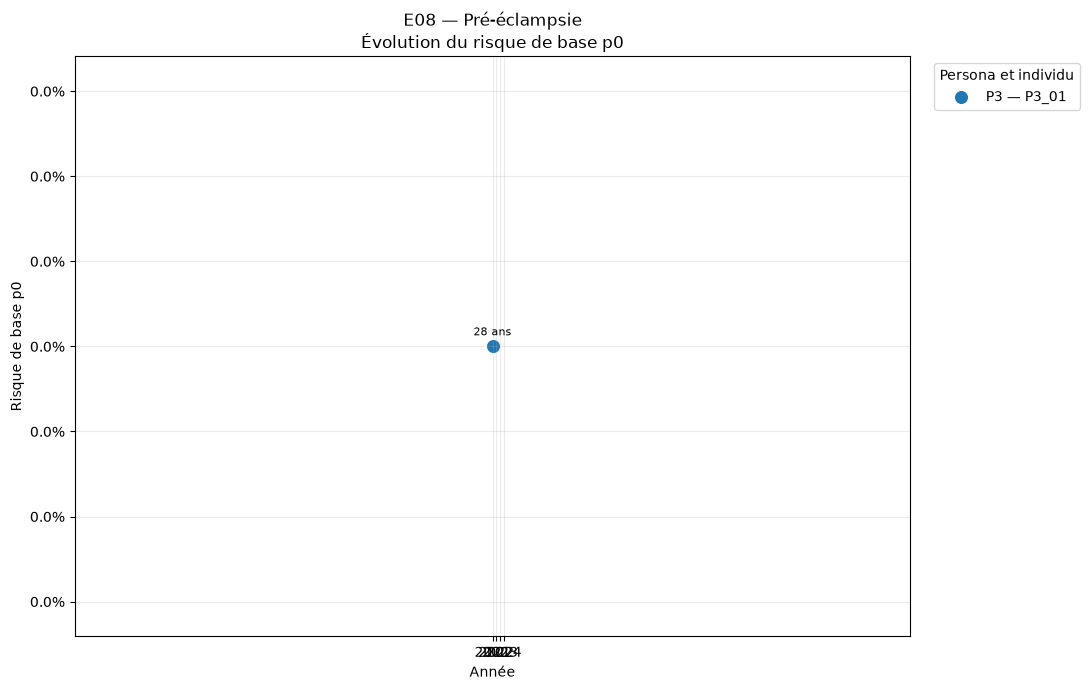

In [45]:
for event_id in event_order:

    event_data = p0[
        p0["event_id"] == event_id
    ].copy()

    fig, ax = plt.subplots(figsize=(11, 7))

    plotted_lines = 0

    for persona in PERSONA_ORDER:

        individual_id = representatives.get(persona)

        if individual_id is None:
            continue

        individual_data = (
            event_data[
                event_data["individual_id"] == individual_id
            ]
            .sort_values("calendar_year")
            .drop_duplicates("calendar_year")
        )

        # Certains événements ne concernent pas tous les personas.
        if individual_data.empty:
            continue

        if len(individual_data) > 1:
            ax.step(
                individual_data["calendar_year"],
                individual_data["p0_value"],
                where="post",
                linewidth=2,
                marker="o",
                label=f"{persona} — {individual_id}",
            )
        else:
            ax.scatter(
                individual_data["calendar_year"],
                individual_data["p0_value"],
                s=70,
                label=f"{persona} — {individual_id}",
            )

        # Affichage de l'âge à chaque observation.
        for row in individual_data.itertuples():
            if pd.notna(row.age):
                ax.annotate(
                    f"{int(row.age)} ans",
                    xy=(row.calendar_year, row.p0_value),
                    xytext=(0, 8),
                    textcoords="offset points",
                    ha="center",
                    fontsize=8,
                )

        plotted_lines += 1

    ax.set_title(
        f"{event_id} — {event_names.get(event_id, event_id)}\n"
        "Évolution du risque de base p0"
    )

    ax.set_xlabel("Année")
    ax.set_ylabel("Risque de base p0")
    ax.yaxis.set_major_formatter(percent_formatter)

    years = sorted(event_data["calendar_year"].unique())
    ax.set_xticks(years)

    ax.grid(alpha=0.25)

    if plotted_lines:
        ax.legend(
            title="Persona et individu",
            bbox_to_anchor=(1.02, 1),
            loc="upper left",
        )

    fig.tight_layout()

    fig.savefig(
        OUTPUT_DIR_P0 / f"3_1_evolution_p0_{event_id}.png",
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()


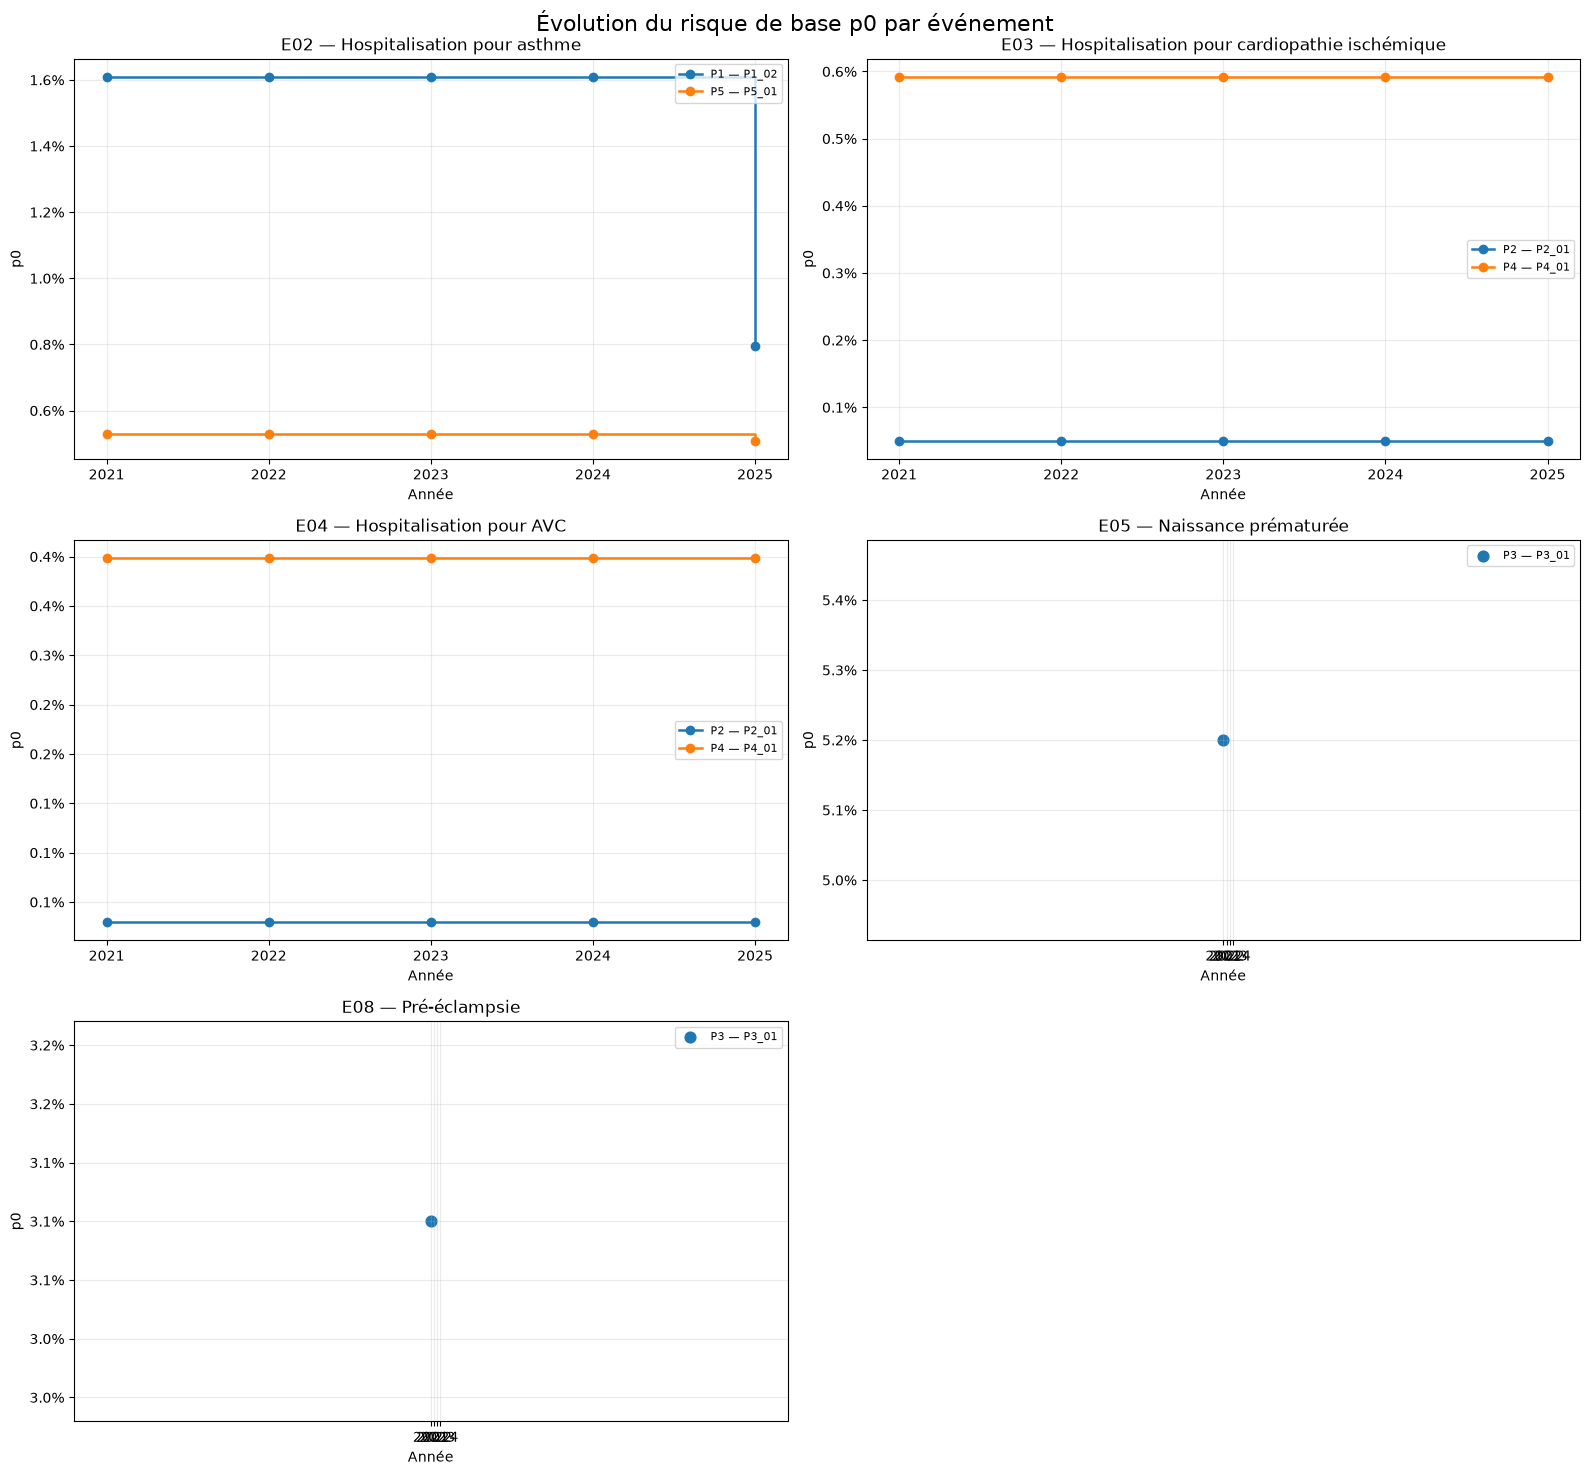

In [40]:
ncols = 2
nrows = math.ceil(len(event_order) / ncols)

fig, axes = plt.subplots(
    nrows=nrows,
    ncols=ncols,
    figsize=(16, 5 * nrows),
    squeeze=False,
)

for ax, event_id in zip(axes.flat, event_order):

    event_data = p0[
        p0["event_id"] == event_id
    ].copy()

    for persona in PERSONA_ORDER:

        individual_id = representatives.get(persona)

        if individual_id is None:
            continue

        individual_data = (
            event_data[
                event_data["individual_id"] == individual_id
            ]
            .sort_values("calendar_year")
            .drop_duplicates("calendar_year")
        )

        if individual_data.empty:
            continue

        if len(individual_data) > 1:
            ax.step(
                individual_data["calendar_year"],
                individual_data["p0_value"],
                where="post",
                linewidth=1.8,
                marker="o",
                label=f"{persona} — {individual_id}",
            )
        else:
            ax.scatter(
                individual_data["calendar_year"],
                individual_data["p0_value"],
                s=60,
                label=f"{persona} — {individual_id}",
            )

    ax.set_title(
        f"{event_id} — {event_names.get(event_id, event_id)}"
    )

    ax.set_xlabel("Année")
    ax.set_ylabel("p0")
    ax.yaxis.set_major_formatter(percent_formatter)

    ax.set_xticks(
        sorted(event_data["calendar_year"].unique())
    )

    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)

for ax in axes.flat[len(event_order):]:
    ax.set_visible(False)

fig.suptitle(
    "Évolution du risque de base p0 par événement",
    fontsize=16,
)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR_P0 / "3_1_evolution_p0_tous_evenements.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

#### Comparaison des p0 entre personas à année fixe

In [41]:
# Recherche de la dernière année présente pour tous les événements.
years_by_event = [
    set(group["calendar_year"].unique())
    for _, group in p0.groupby("event_id")
]

common_years = set.intersection(*years_by_event)

if not common_years:
    raise ValueError(
        "Aucune année commune à tous les événements."
    )

FIXED_YEAR = max(common_years)

print(
    f"Année retenue pour la comparaison : {FIXED_YEAR}"
)

fixed_year_data = p0[
    p0["calendar_year"] == FIXED_YEAR
].copy()

# Moyenne des p0 individuels par persona et événement.
p0_comparison = (
    fixed_year_data
    .groupby(
        ["event_id", "persona_id"],
        as_index=False,
    )
    .agg(
        mean_p0=("p0_value", "mean"),
        min_p0=("p0_value", "min"),
        max_p0=("p0_value", "max"),
        n_individuals=("individual_id", "nunique"),
    )
)

comparison_table = (
    p0_comparison
    .pivot(
        index="event_id",
        columns="persona_id",
        values="mean_p0",
    )
    .reindex(
        index=event_order,
        columns=PERSONA_ORDER,
    )
)

comparison_table.to_csv(
    OUTPUT_DIR_P0
    / f"3_2_comparaison_p0_{FIXED_YEAR}.csv"
)

Année retenue pour la comparaison : 2024


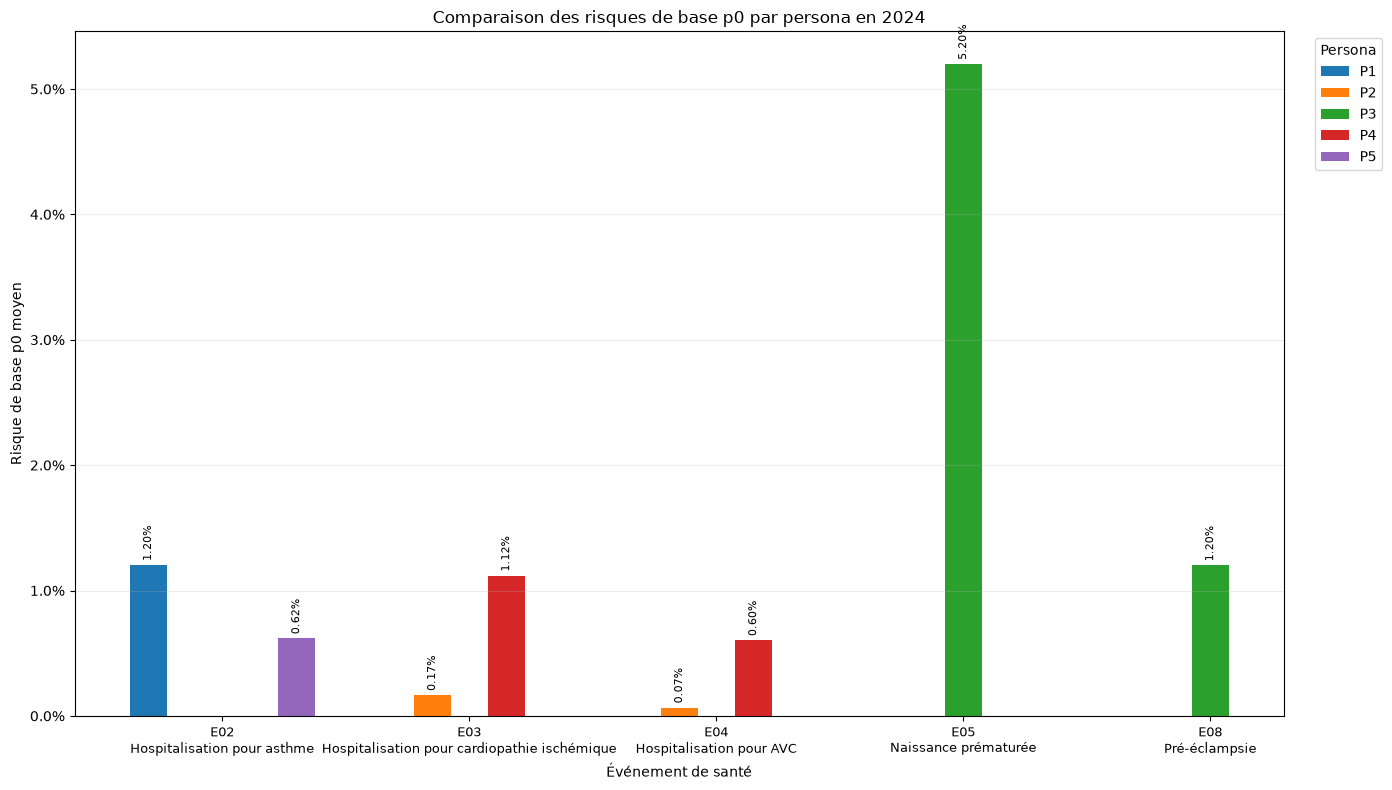

In [42]:
x = np.arange(len(comparison_table.index))
width = 0.15

fig, ax = plt.subplots(figsize=(14, 8))

for persona_index, persona in enumerate(PERSONA_ORDER):

    values = comparison_table[persona].to_numpy()

    positions = (
        x
        - width * (len(PERSONA_ORDER) - 1) / 2
        + persona_index * width
    )

    valid = ~np.isnan(values)

    bars = ax.bar(
        positions[valid],
        values[valid],
        width=width,
        label=persona,
    )

    ax.bar_label(
        bars,
        labels=[
            f"{value:.2%}"
            for value in values[valid]
        ],
        padding=3,
        rotation=90,
        fontsize=8,
    )

event_tick_labels = [
    f"{event_id}\n{event_names.get(event_id, '')}"
    for event_id in comparison_table.index
]

ax.set_title(
    f"Comparaison des risques de base p0 par persona en {FIXED_YEAR}"
)

ax.set_xlabel("Événement de santé")
ax.set_ylabel("Risque de base p0 moyen")

ax.set_xticks(x)
ax.set_xticklabels(
    event_tick_labels,
    fontsize=9,
)

ax.yaxis.set_major_formatter(percent_formatter)

ax.legend(
    title="Persona",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
)

ax.grid(axis="y", alpha=0.25)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR_P0
    / f"3_2_comparaison_p0_personas_{FIXED_YEAR}.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()


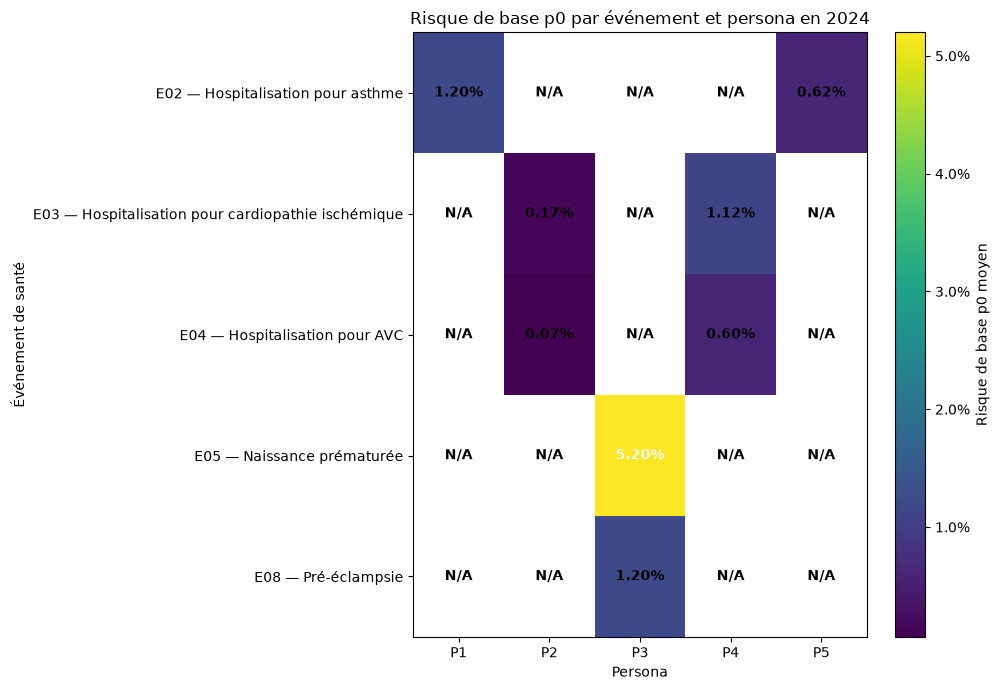

In [43]:
heatmap_values = comparison_table.to_numpy()

fig, ax = plt.subplots(figsize=(10, 7))

image = ax.imshow(
    heatmap_values,
    aspect="auto",
)

ax.set_xticks(
    np.arange(len(comparison_table.columns))
)
ax.set_xticklabels(
    comparison_table.columns
)

ax.set_yticks(
    np.arange(len(comparison_table.index))
)
ax.set_yticklabels(
    [
        f"{event_id} — {event_names.get(event_id, '')}"
        for event_id in comparison_table.index
    ]
)

finite_values = heatmap_values[
    np.isfinite(heatmap_values)
]

threshold = (
    finite_values.min()
    + (
        finite_values.max()
        - finite_values.min()
    ) / 2
    if finite_values.size
    else 0
)

for row_index in range(comparison_table.shape[0]):
    for column_index in range(comparison_table.shape[1]):

        value = comparison_table.iloc[
            row_index,
            column_index,
        ]

        if pd.isna(value):
            label = "N/A"
            text_color = "black"
        else:
            label = f"{value:.2%}"
            text_color = (
                "white"
                if value > threshold
                else "black"
            )

        ax.text(
            column_index,
            row_index,
            label,
            ha="center",
            va="center",
            color=text_color,
            fontsize=10,
            fontweight="bold",
        )

colorbar = fig.colorbar(image, ax=ax)
colorbar.set_label("Risque de base p0 moyen")
colorbar.ax.yaxis.set_major_formatter(
    percent_formatter
)

ax.set_title(
    f"Risque de base p0 par événement et persona en {FIXED_YEAR}"
)
ax.set_xlabel("Persona")
ax.set_ylabel("Événement de santé")

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR_P0
    / f"3_2_heatmap_p0_personas_{FIXED_YEAR}.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

## Trajectoires d'exposition individuelles

In [46]:
EXPOSURES_FILE = Path("./outputs/individual_exposures.csv.gz")
WINDOWS_FILE = Path("./outputs/exposure_windows.csv.gz")

OUTPUT_DIR_EXPO = Path("./figures/visualisations_expositions")
OUTPUT_DIR_EXPO.mkdir(exist_ok=True)

PERSONA_ORDER = ["P1", "P2", "P3", "P4", "P5"]

# Seuil OMS PM2.5, moyenne sur 24 heures
WHO_PM25_24H = 15.0

# None = sélection automatique de la première année commune
PLOT_YEAR = None

CHUNKSIZE = 500_000

#### Trajectoire annuelle d'un individu par persona

In [47]:
windows = pd.read_csv(
    WINDOWS_FILE,
    usecols=[
        "individual_id",
        "persona_id",
        "household_id",
        "pollutant",
        "window_type",
        "date",
        "year",
        "mean_exposure",
    ],
)

daily_pm25 = windows[
    windows["pollutant"].eq("PM25")
    & windows["window_type"].eq("daily")
].copy()

daily_pm25["date"] = pd.to_datetime(
    daily_pm25["date"],
    errors="coerce",
)

daily_pm25["year"] = pd.to_numeric(
    daily_pm25["year"],
    errors="coerce",
)

daily_pm25["mean_exposure"] = pd.to_numeric(
    daily_pm25["mean_exposure"],
    errors="coerce",
)

daily_pm25 = daily_pm25.dropna(
    subset=[
        "individual_id",
        "persona_id",
        "date",
        "year",
        "mean_exposure",
    ]
)

daily_pm25["year"] = daily_pm25["year"].astype(int)

In [48]:
years_by_persona = (
    daily_pm25
    .groupby("persona_id")["year"]
    .apply(set)
)

common_years = set.intersection(
    *years_by_persona.tolist()
)

if not common_years:
    raise ValueError(
        "Aucune année commune à tous les personas."
    )

if PLOT_YEAR is None:
    PLOT_YEAR = min(common_years)

if PLOT_YEAR not in common_years:
    raise ValueError(
        f"L'année {PLOT_YEAR} n'est pas disponible "
        "pour tous les personas."
    )

year_daily = daily_pm25[
    daily_pm25["year"].eq(PLOT_YEAR)
].copy()

In [49]:
individual_annual_means = (
    year_daily
    .groupby(
        ["persona_id", "individual_id"],
        as_index=False,
    )
    .agg(
        annual_mean_exposure=(
            "mean_exposure",
            "mean",
        )
    )
)

individual_annual_means["persona_median"] = (
    individual_annual_means
    .groupby("persona_id")[
        "annual_mean_exposure"
    ]
    .transform("median")
)

individual_annual_means["distance_to_median"] = (
    individual_annual_means[
        "annual_mean_exposure"
    ]
    - individual_annual_means[
        "persona_median"
    ]
).abs()

representatives = (
    individual_annual_means
    .sort_values(
        [
            "persona_id",
            "distance_to_median",
            "individual_id",
        ]
    )
    .drop_duplicates("persona_id")
    [
        [
            "persona_id",
            "individual_id",
            "annual_mean_exposure",
        ]
    ]
)

representative_map = dict(
    zip(
        representatives["persona_id"],
        representatives["individual_id"],
    )
)

print("Individus représentatifs :")
print(representatives.to_string(index=False))

Individus représentatifs :
persona_id individual_id  annual_mean_exposure
        P1         P1_01              2.134665
        P2         P2_04              7.752908
        P3         P3_03              7.752908
        P4         P4_03             10.053518
        P5         P5_01              8.524484


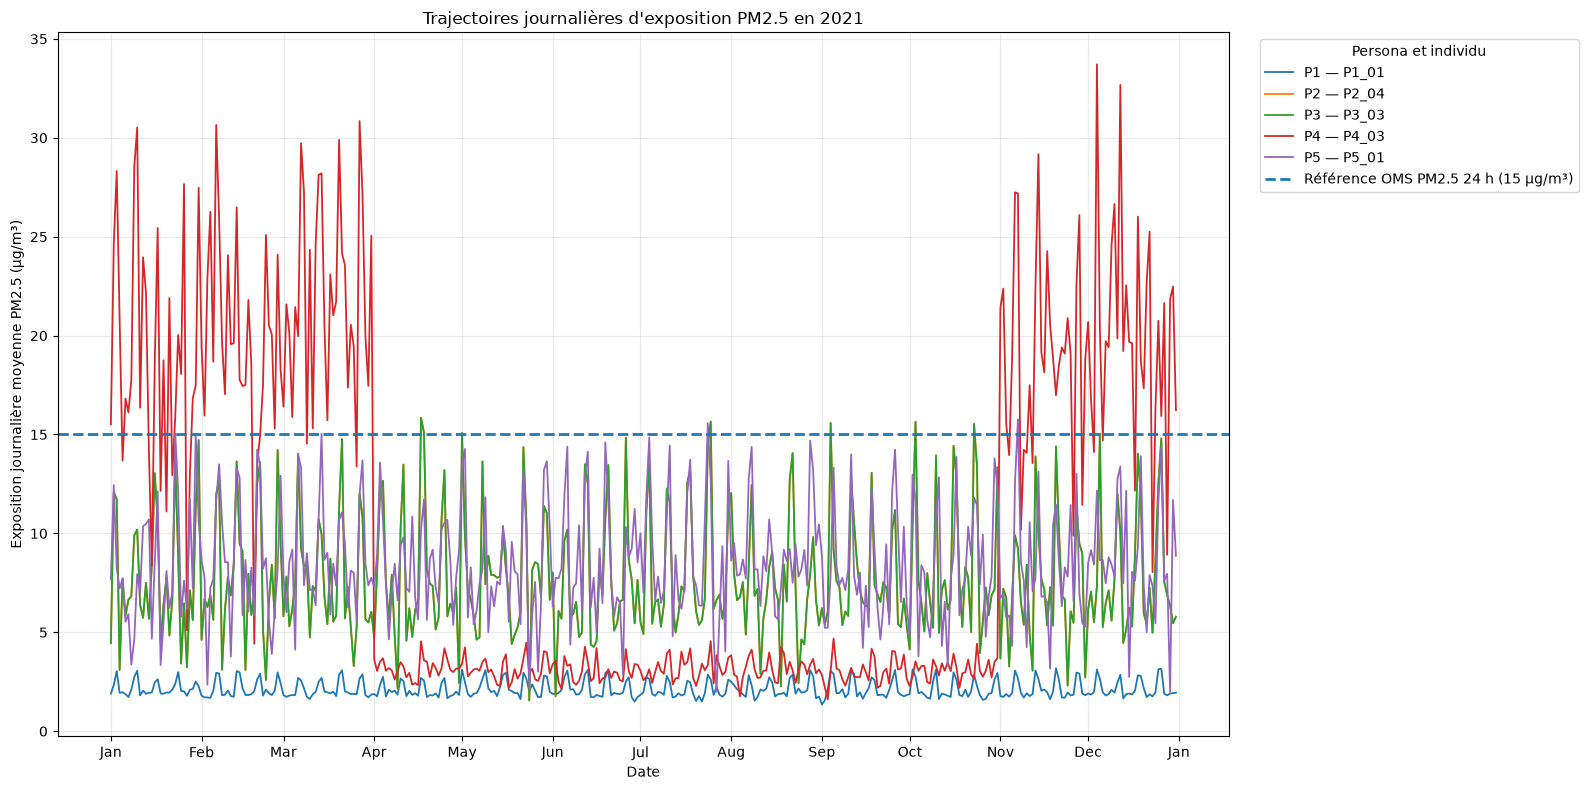

In [51]:
fig, ax = plt.subplots(figsize=(16, 8))

for persona in PERSONA_ORDER:

    individual_id = representative_map.get(persona)

    if individual_id is None:
        continue

    individual_data = (
        year_daily[
            year_daily["individual_id"].eq(
                individual_id
            )
        ]
        .sort_values("date")
    )

    ax.plot(
        individual_data["date"],
        individual_data["mean_exposure"],
        linewidth=1.3,
        label=f"{persona} — {individual_id}",
    )

ax.axhline(
    WHO_PM25_24H,
    linestyle="--",
    linewidth=2,
    label=(
        "Référence OMS PM2.5 24 h "
        f"({WHO_PM25_24H:g} µg/m³)"
    ),
)

ax.set_title(
    f"Trajectoires journalières d'exposition PM2.5 en {PLOT_YEAR}"
)
ax.set_xlabel("Date")
ax.set_ylabel("Exposition journalière moyenne PM2.5 (µg/m³)")

ax.xaxis.set_major_locator(
    mdates.MonthLocator()
)
ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%b")
)

ax.grid(alpha=0.25)

ax.legend(
    title="Persona et individu",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR_EXPO
    / f"4_1_trajectoires_annuelles_{PLOT_YEAR}.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

In [52]:
metadata_columns = [
    "individual_id",
    "persona_id",
    "household_id",
    "presence_template",
]

metadata_parts = []

for chunk in pd.read_csv(
    EXPOSURES_FILE,
    usecols=metadata_columns,
    chunksize=CHUNKSIZE,
):
    metadata_parts.append(
        chunk.drop_duplicates()
    )

metadata = (
    pd.concat(
        metadata_parts,
        ignore_index=True,
    )
    .drop_duplicates()
)

#### Sélection automatique d'un logement : celui qui possède le plus de profils de présence différents

In [53]:
household_summary = (
    metadata
    .groupby(
        "household_id",
        as_index=False,
    )
    .agg(
        n_individuals=(
            "individual_id",
            "nunique",
        ),
        n_presence_templates=(
            "presence_template",
            "nunique",
        ),
    )
)

eligible_households = (
    household_summary[
        household_summary["n_individuals"].ge(2)
        & household_summary[
            "n_presence_templates"
        ].ge(2)
    ]
    .sort_values(
        [
            "n_presence_templates",
            "n_individuals",
            "household_id",
        ],
        ascending=[False, False, True],
    )
)

if eligible_households.empty:
    raise ValueError(
        "Aucun logement ne contient au moins deux "
        "individus ayant des profils de présence différents."
    )

selected_household = (
    eligible_households.iloc[0]["household_id"]
)

print(
    "\nLogement sélectionné pour 4.2 et 4.3 :",
    selected_household,
)


Logement sélectionné pour 4.2 et 4.3 : H01


#### Chargement des données 15 minutes du logement sélectionné

In [54]:
exposure_columns = [
    "individual_id",
    "persona_id",
    "household_id",
    "timestamp",
    "is_home",
    "presence_template",
    "pm25_indoor",
    "pm25_residential_exposure",
]

household_parts = []

year_prefix = str(PLOT_YEAR)

for chunk in pd.read_csv(
    EXPOSURES_FILE,
    usecols=exposure_columns,
    chunksize=CHUNKSIZE,
):
    timestamp_as_text = (
        chunk["timestamp"].astype(str)
    )

    selected_rows = (
        chunk["household_id"].eq(
            selected_household
        )
        & timestamp_as_text.str.startswith(
            year_prefix
        )
    )

    if selected_rows.any():
        household_parts.append(
            chunk.loc[selected_rows].copy()
        )

if not household_parts:
    raise ValueError(
        f"Aucune exposition trouvée pour "
        f"{selected_household} en {PLOT_YEAR}."
    )

household_data = pd.concat(
    household_parts,
    ignore_index=True,
)

household_data["timestamp"] = pd.to_datetime(
    household_data["timestamp"],
    errors="coerce",
)

household_data["is_home"] = pd.to_numeric(
    household_data["is_home"],
    errors="coerce",
).fillna(0).astype(int)

for column in [
    "pm25_indoor",
    "pm25_residential_exposure",
]:
    household_data[column] = pd.to_numeric(
        household_data[column],
        errors="coerce",
    )

household_data = household_data.dropna(
    subset=[
        "timestamp",
        "individual_id",
        "pm25_indoor",
        "pm25_residential_exposure",
    ]
)

# W-SUN : semaine du lundi au dimanche
household_data["week_start"] = (
    household_data["timestamp"]
    .dt.to_period("W-SUN")
    .dt.start_time
)


# ------------------------------------------------------------
# Conservation des semaines complètes de 7 × 96 créneaux
# ------------------------------------------------------------

week_slot_counts = (
    household_data
    .groupby("week_start")["timestamp"]
    .nunique()
)

complete_weeks = week_slot_counts[
    week_slot_counts.ge(7 * 96)
].index

if len(complete_weeks) == 0:
    maximum_slots = week_slot_counts.max()

    complete_weeks = week_slot_counts[
        week_slot_counts.eq(maximum_slots)
    ].index


####  Concentration du logement vs exposition individuelle


Visualisation 4.2 : P2_01 Personne1 2021-01-04


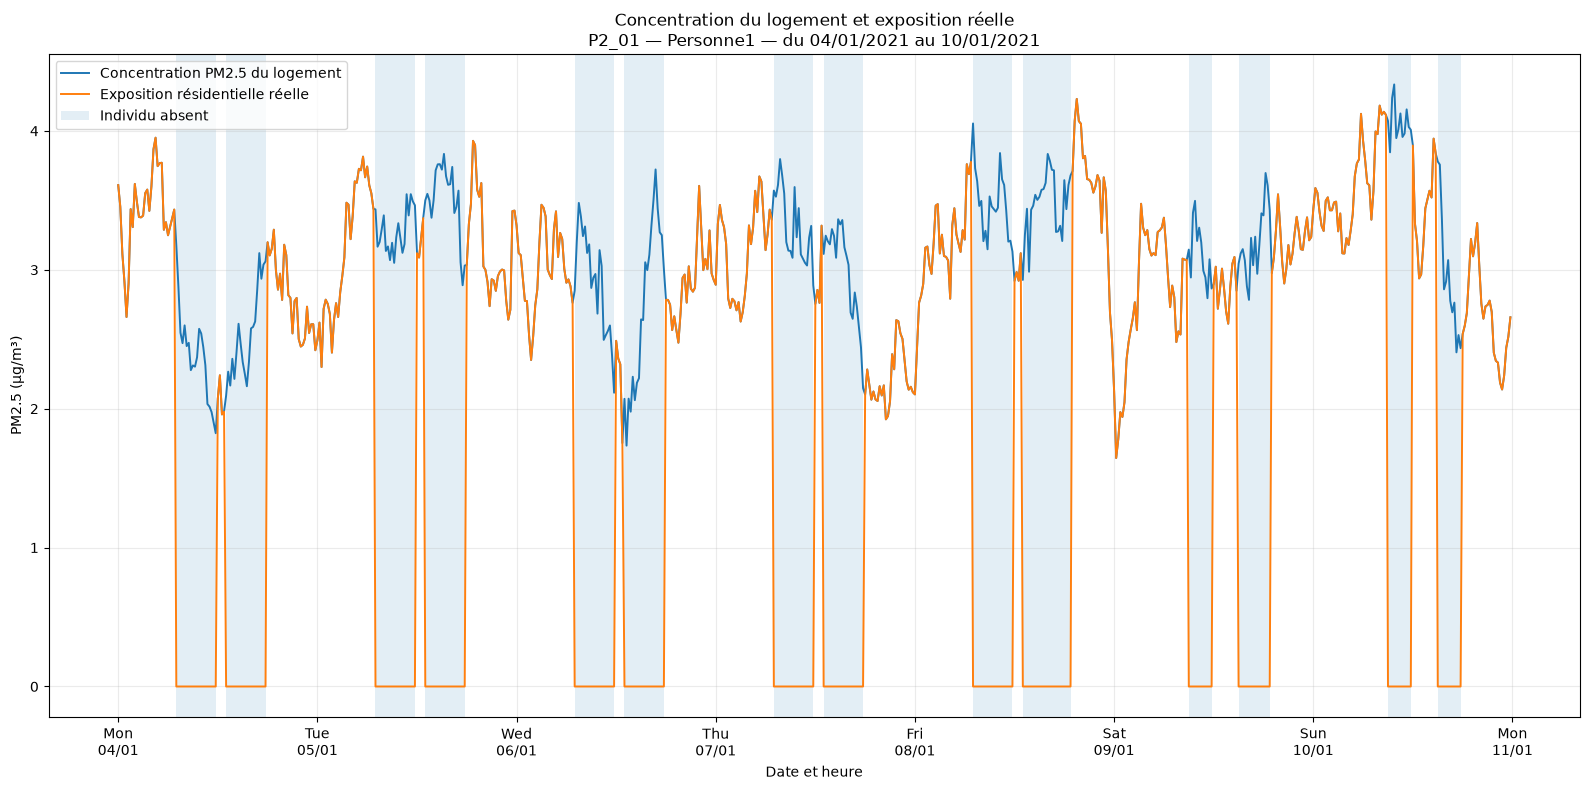

In [56]:
weekly_presence = (
    household_data[
        household_data["week_start"].isin(
            complete_weeks
        )
    ]
    .groupby(
        ["individual_id", "week_start"],
        as_index=False,
    )
    .agg(
        home_slots=("is_home", "sum"),
        total_slots=("is_home", "size"),
    )
)

weekly_presence["absent_slots"] = (
    weekly_presence["total_slots"]
    - weekly_presence["home_slots"]
)

# Individu et semaine présentant le plus d'absences
selected_presence = (
    weekly_presence
    .sort_values(
        [
            "absent_slots",
            "individual_id",
            "week_start",
        ],
        ascending=[False, True, True],
    )
    .iloc[0]
)

selected_individual = (
    selected_presence["individual_id"]
)

selected_week = (
    selected_presence["week_start"]
)

week_data = (
    household_data[
        household_data["individual_id"].eq(
            selected_individual
        )
        & household_data["week_start"].eq(
            selected_week
        )
    ]
    .sort_values("timestamp")
)

presence_template = (
    week_data["presence_template"].iloc[0]
)

print(
    "\nVisualisation 4.2 :",
    selected_individual,
    presence_template,
    selected_week.date(),
)


fig, ax = plt.subplots(figsize=(16, 8))

ax.plot(
    week_data["timestamp"],
    week_data["pm25_indoor"],
    linewidth=1.4,
    label="Concentration PM2.5 du logement",
)

ax.plot(
    week_data["timestamp"],
    week_data[
        "pm25_residential_exposure"
    ],
    linewidth=1.4,
    label="Exposition résidentielle réelle",
)

# Zones correspondant aux absences
ax.fill_between(
    week_data["timestamp"],
    0,
    1,
    where=week_data["is_home"].eq(0),
    transform=ax.get_xaxis_transform(),
    step="post",
    alpha=0.12,
    label="Individu absent",
)

week_end = (
    selected_week
    + pd.Timedelta(days=6)
)

ax.set_title(
    f"Concentration du logement et exposition réelle\n"
    f"{selected_individual} — {presence_template} — "
    f"du {selected_week:%d/%m/%Y} "
    f"au {week_end:%d/%m/%Y}"
)

ax.set_xlabel("Date et heure")
ax.set_ylabel("PM2.5 (µg/m³)")

ax.xaxis.set_major_locator(
    mdates.DayLocator()
)
ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%a\n%d/%m")
)

ax.grid(alpha=0.25)
ax.legend()

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR_EXPO
    / (
        "4_2_concentration_vs_exposition_"
        f"{selected_individual}_"
        f"{selected_week:%Y%m%d}.png"
    ),
    dpi=300,
    bbox_inches="tight",
)

plt.show()


#### Deux occupants du même logement


Visualisation 4.3 : P2_01 Personne1 vs P3_01 Personne2 2021-11-01


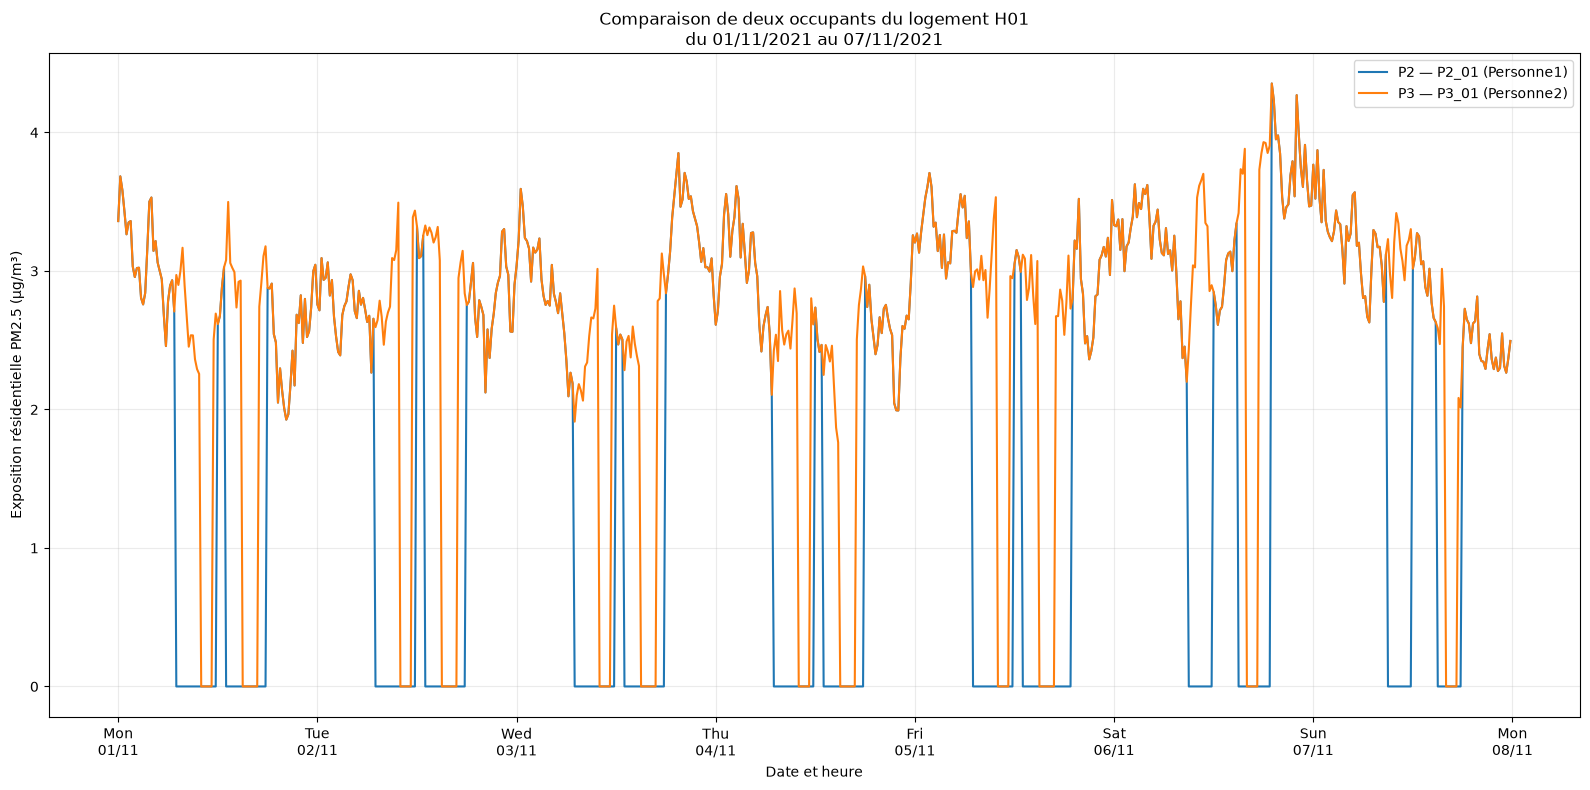

In [58]:
template_by_individual = (
    metadata[
        metadata["household_id"].eq(
            selected_household
        )
    ]
    .drop_duplicates("individual_id")
    .set_index("individual_id")[
        "presence_template"
    ]
    .to_dict()
)

weekly_presence["home_fraction"] = (
    weekly_presence["home_slots"]
    / weekly_presence["total_slots"]
)

presence_pivot = weekly_presence.pivot(
    index="week_start",
    columns="individual_id",
    values="home_fraction",
)

pair_candidates = []

for individual_1, individual_2 in combinations(
    presence_pivot.columns,
    2,
):
    template_1 = template_by_individual.get(
        individual_1
    )
    template_2 = template_by_individual.get(
        individual_2
    )

    # On impose deux profils de présence différents
    if template_1 == template_2:
        continue

    differences = (
        presence_pivot[individual_1]
        - presence_pivot[individual_2]
    ).abs().dropna()

    if differences.empty:
        continue

    pair_week = differences.idxmax()
    maximum_difference = differences.loc[
        pair_week
    ]

    pair_candidates.append(
        (
            maximum_difference,
            pair_week,
            individual_1,
            individual_2,
        )
    )

if not pair_candidates:
    raise ValueError(
        "Impossible de trouver deux occupants ayant "
        "des profils de présence différents."
    )

(
    maximum_difference,
    comparison_week,
    individual_1,
    individual_2,
) = max(
    pair_candidates,
    key=lambda item: item[0],
)

comparison_data = (
    household_data[
        household_data["individual_id"].isin(
            [individual_1, individual_2]
        )
        & household_data["week_start"].eq(
            comparison_week
        )
    ]
    .sort_values(
        ["individual_id", "timestamp"]
    )
)

print(
    "\nVisualisation 4.3 :",
    individual_1,
    template_by_individual[individual_1],
    "vs",
    individual_2,
    template_by_individual[individual_2],
    comparison_week.date(),
)


fig, ax = plt.subplots(figsize=(16, 8))

for individual_id, individual_data in (
    comparison_data.groupby("individual_id")
):
    template = template_by_individual[
        individual_id
    ]

    persona = (
        individual_data["persona_id"].iloc[0]
    )

    ax.plot(
        individual_data["timestamp"],
        individual_data[
            "pm25_residential_exposure"
        ],
        linewidth=1.5,
        label=(
            f"{persona} — {individual_id} "
            f"({template})"
        ),
    )

comparison_week_end = (
    comparison_week
    + pd.Timedelta(days=6)
)

ax.set_title(
    f"Comparaison de deux occupants du logement "
    f"{selected_household}\n"
    f"du {comparison_week:%d/%m/%Y} "
    f"au {comparison_week_end:%d/%m/%Y}"
)

ax.set_xlabel("Date et heure")
ax.set_ylabel(
    "Exposition résidentielle PM2.5 (µg/m³)"
)

ax.xaxis.set_major_locator(
    mdates.DayLocator()
)
ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%a\n%d/%m")
)

ax.grid(alpha=0.25)
ax.legend()

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR_EXPO
    / (
        "4_3_comparaison_occupants_"
        f"{selected_household}_"
        f"{comparison_week:%Y%m%d}.png"
    ),
    dpi=300,
    bbox_inches="tight",
)

plt.show()

## méthodes de détection — Moyenne, Maximum, MIL

In [59]:
THRESHOLDS_FILE = Path("./outputs/exposure_thresholds.csv.gz")

OUTPUT_DIR_DETECT = Path("./figures/visualisations_detection")
OUTPUT_DIR_DETECT.mkdir(exist_ok=True)

POLLUTANT = "PM25"
WINDOW_TYPE = "daily"

SCENARIO_ORDER = [
    "clean",
    "cooking",
    "tobacco",
    "biomass_extreme",
]

SCENARIO_LABELS = {
    "clean": "Propre",
    "cooking": "Cuisson",
    "tobacco": "Tabac",
    "biomass_extreme": "Biomasse extrême",
}

METHOD_COLUMNS = {
    "Moyenne": "mean_exceedance",
    "Maximum": "max_exceedance",
    "MIL": "mil_exceedance",
}


In [60]:
thresholds = pd.read_csv(THRESHOLDS_FILE)

required_columns = {
    "individual_id",
    "persona_id",
    "household_id",
    "pollutant",
    "window_type",
    "date",
    "mean_exceedance",
    "max_exceedance",
    "mil_exceedance",
    "proportion_above_threshold",
}

missing_columns = required_columns.difference(thresholds.columns)

if missing_columns:
    raise ValueError(
        "Colonnes manquantes dans exposure_thresholds : "
        + ", ".join(sorted(missing_columns))
    )

# Récupération du scénario associé à chaque logement.
household_scenarios = (
    pd.read_csv(
        CONCENTRATIONS_FILE,
        usecols=["household_id", "emission_scenario"],
    )
    .drop_duplicates()
)

scenario_counts = (
    household_scenarios
    .groupby("household_id")["emission_scenario"]
    .nunique()
)

if scenario_counts.max() > 1:
    raise ValueError(
        "Au moins un logement possède plusieurs scénarios."
    )

data = (
    thresholds[
        thresholds["pollutant"].eq(POLLUTANT)
        & thresholds["window_type"].eq(WINDOW_TYPE)
    ]
    .merge(
        household_scenarios,
        on="household_id",
        how="left",
        validate="many_to_one",
    )
)

if data["emission_scenario"].isna().any():
    missing_households = (
        data.loc[
            data["emission_scenario"].isna(),
            "household_id",
        ]
        .drop_duplicates()
        .astype(str)
        .tolist()
    )

    raise ValueError(
        "Scénario absent pour les logements : "
        + ", ".join(missing_households)
    )

data["date"] = pd.to_datetime(
    data["date"],
    errors="coerce",
)

for column in [
    "mean_exceedance",
    "max_exceedance",
    "mil_exceedance",
    "proportion_above_threshold",
]:
    data[column] = pd.to_numeric(
        data[column],
        errors="coerce",
    )

data = data.dropna(
    subset=[
        "individual_id",
        "date",
        "emission_scenario",
        *METHOD_COLUMNS.values(),
        "proportion_above_threshold",
    ]
)

scenario_order = [
    scenario
    for scenario in SCENARIO_ORDER
    if scenario in data["emission_scenario"].unique()
]

#### Taux de dépassement par méthode et profil


Taux de dépassement par scénario :
                   Moyenne  Maximum     MIL
emission_scenario                          
clean                 0.00     0.00    0.00
cooking               3.25    98.37   95.35
tobacco              19.52   100.00  100.00
biomass_extreme      35.31    41.22   40.16


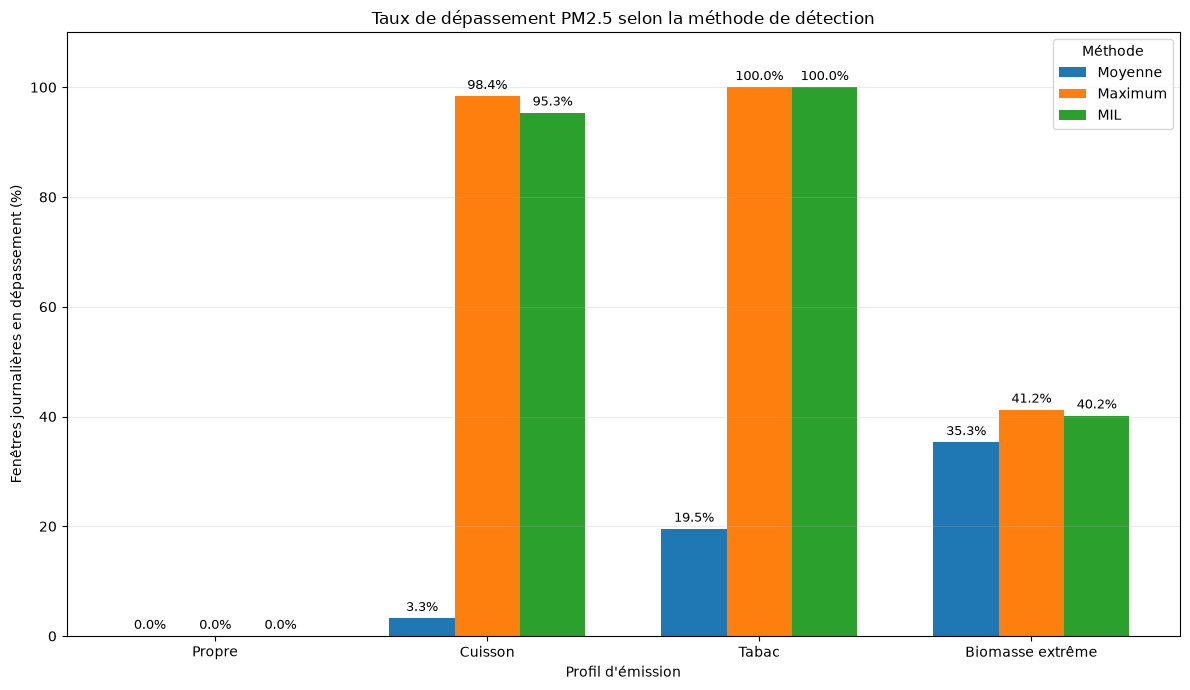

In [61]:
exceedance_rates = (
    data
    .groupby("emission_scenario")[
        list(METHOD_COLUMNS.values())
    ]
    .mean()
    .mul(100)
    .reindex(scenario_order)
    .rename(
        columns={
            column: method
            for method, column in METHOD_COLUMNS.items()
        }
    )
)

print("\nTaux de dépassement par scénario :")
print(exceedance_rates.round(2))

exceedance_rates.to_csv(
    OUTPUT_DIR_DETECT / "5_1_taux_depassement.csv"
)

x = np.arange(len(exceedance_rates))
width = 0.24

fig, ax = plt.subplots(figsize=(12, 7))

for method_index, method in enumerate(METHOD_COLUMNS):
    positions = (
        x
        - width * (len(METHOD_COLUMNS) - 1) / 2
        + method_index * width
    )

    values = exceedance_rates[method].to_numpy()

    bars = ax.bar(
        positions,
        values,
        width=width,
        label=method,
    )

    ax.bar_label(
        bars,
        labels=[
            f"{value:.1f}%"
            for value in values
        ],
        padding=3,
        fontsize=9,
    )

ax.set_title(
    "Taux de dépassement PM2.5 selon la méthode de détection"
)
ax.set_xlabel("Profil d'émission")
ax.set_ylabel("Fenêtres journalières en dépassement (%)")

ax.set_xticks(x)
ax.set_xticklabels(
    [
        SCENARIO_LABELS.get(scenario, scenario)
        for scenario in exceedance_rates.index
    ]
)

ax.set_ylim(
    0,
    min(
        110,
        max(
            10,
            exceedance_rates.to_numpy().max() + 12,
        ),
    ),
)

ax.legend(title="Méthode")
ax.grid(axis="y", alpha=0.25)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR_DETECT / "5_1_taux_depassement_par_methode.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

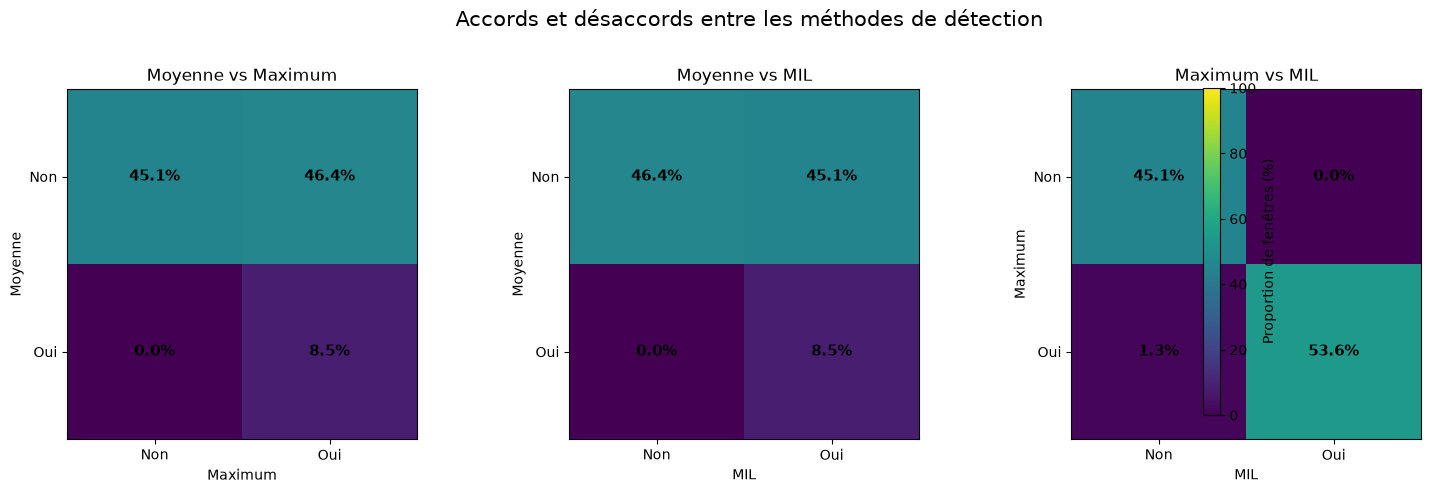

In [62]:
def pairwise_agreement_matrix(
    frame,
    first_column,
    second_column,
):
    """
    Matrice 2 × 2 en pourcentage.

    Lignes :
        décision de la première méthode.

    Colonnes :
        décision de la seconde méthode.
    """
    matrix = pd.crosstab(
        frame[first_column].astype(int),
        frame[second_column].astype(int),
        normalize="all",
    )

    return (
        matrix
        .reindex(
            index=[0, 1],
            columns=[0, 1],
            fill_value=0,
        )
        .mul(100)
    )


method_pairs = list(
    combinations(METHOD_COLUMNS.items(), 2)
)

fig, axes = plt.subplots(
    nrows=1,
    ncols=len(method_pairs),
    figsize=(16, 5),
    squeeze=False,
)

for ax, (
    (first_name, first_column),
    (second_name, second_column),
) in zip(axes.flat, method_pairs):

    matrix = pairwise_agreement_matrix(
        data,
        first_column,
        second_column,
    )

    image = ax.imshow(
        matrix.to_numpy(),
        vmin=0,
        vmax=100,
        aspect="equal",
    )

    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Non", "Oui"])

    ax.set_yticks([0, 1])
    ax.set_yticklabels(["Non", "Oui"])

    ax.set_xlabel(second_name)
    ax.set_ylabel(first_name)
    ax.set_title(f"{first_name} vs {second_name}")

    for row_index in range(2):
        for column_index in range(2):
            value = matrix.iloc[
                row_index,
                column_index,
            ]

            ax.text(
                column_index,
                row_index,
                f"{value:.1f}%",
                ha="center",
                va="center",
                fontsize=11,
                fontweight="bold",
            )

fig.colorbar(
    image,
    ax=axes.ravel().tolist(),
    label="Proportion de fenêtres (%)",
    shrink=0.85,
)

fig.suptitle(
    "Accords et désaccords entre les méthodes de détection",
    fontsize=15,
)

fig.subplots_adjust(
    left=0.06,
    right=0.92,
    bottom=0.12,
    top=0.82,
    wspace=0.35,
)

fig.savefig(
    OUTPUT_DIR_DETECT / "5_2_matrices_desaccord_pairwise.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()


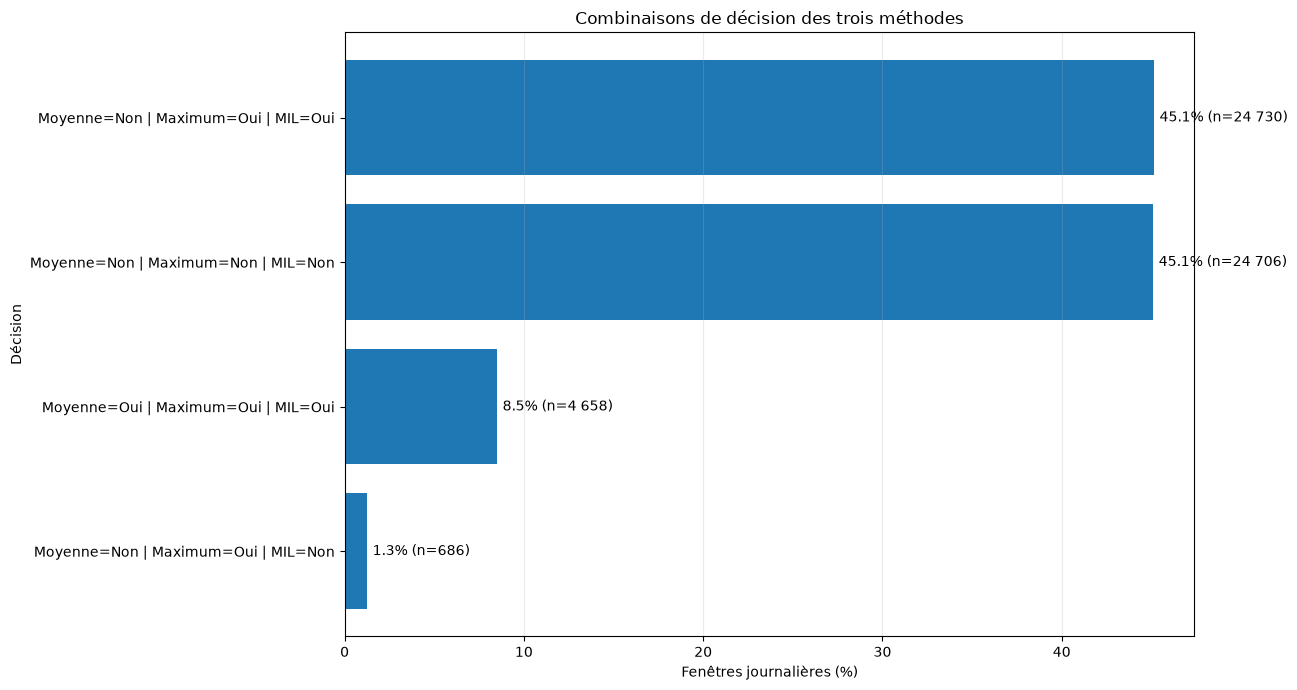


Fenêtres avec désaccord : 25 416 / 54 780 (46.40 %)


In [63]:
method_column_names = list(
    METHOD_COLUMNS.values()
)

state_combinations = (
    data
    .groupby(method_column_names)
    .size()
    .rename("n_windows")
    .reset_index()
)

state_combinations["percentage"] = (
    state_combinations["n_windows"]
    / len(data)
    * 100
)

state_combinations["state"] = (
    "Moyenne="
    + state_combinations["mean_exceedance"].map(
        {0: "Non", 1: "Oui"}
    )
    + " | Maximum="
    + state_combinations["max_exceedance"].map(
        {0: "Non", 1: "Oui"}
    )
    + " | MIL="
    + state_combinations["mil_exceedance"].map(
        {0: "Non", 1: "Oui"}
    )
)

state_combinations = state_combinations.sort_values(
    "percentage",
    ascending=True,
)

state_combinations.to_csv(
    OUTPUT_DIR_DETECT / "5_2_combinaisons_methodes.csv",
    index=False,
)

fig, ax = plt.subplots(figsize=(13, 7))

bars = ax.barh(
    state_combinations["state"],
    state_combinations["percentage"],
)

labels = [
    (
        f"{percentage:.1f}% "
        f"(n={count:,})"
    ).replace(",", " ")
    for percentage, count in zip(
        state_combinations["percentage"],
        state_combinations["n_windows"],
    )
]

ax.bar_label(
    bars,
    labels=labels,
    padding=4,
)

ax.set_title(
    "Combinaisons de décision des trois méthodes"
)
ax.set_xlabel("Fenêtres journalières (%)")
ax.set_ylabel("Décision")
ax.grid(axis="x", alpha=0.25)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR_DETECT / "5_2_combinaisons_trois_methodes.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()


# Nombre de fenêtres où les trois méthodes ne donnent
# pas toutes la même décision.
disagreement_mask = (
    data[method_column_names]
    .nunique(axis=1)
    .gt(1)
)

n_divergent = int(disagreement_mask.sum())
divergent_rate = 100 * n_divergent / len(data)

print(
    "\nFenêtres avec désaccord : "
    f"{n_divergent:,} / {len(data):,} "
    f"({divergent_rate:.2f} %)".replace(",", " ")
)

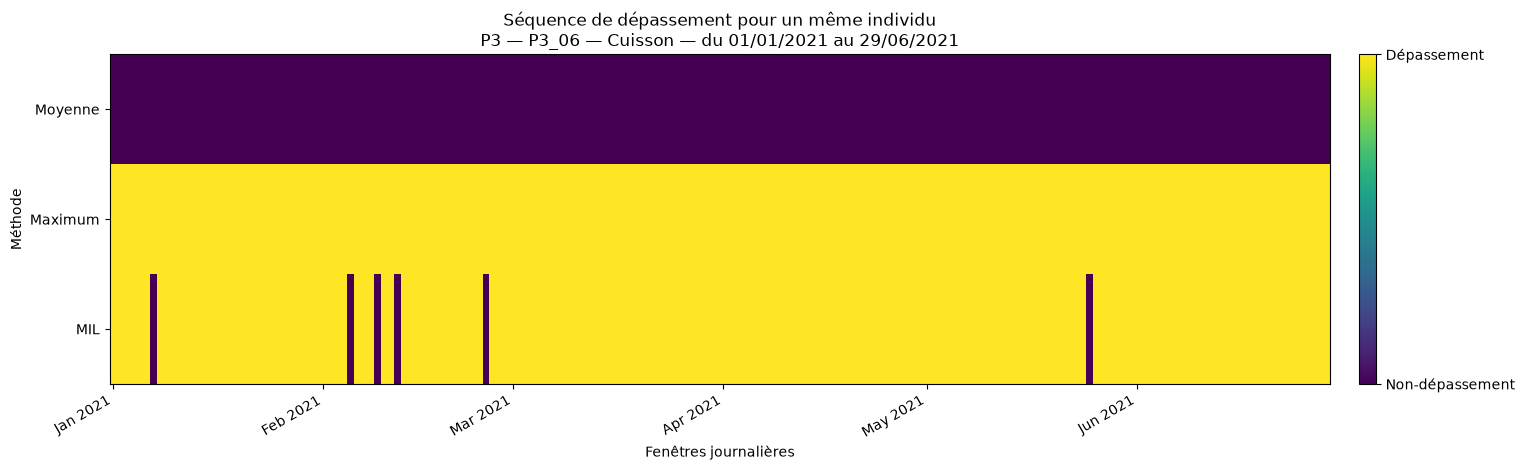

In [64]:
data["method_disagreement"] = (
    data[method_column_names]
    .nunique(axis=1)
    .gt(1)
    .astype(int)
)

# Sélection de l'individu ayant la plus forte proportion
# de jours avec désaccord.
individual_disagreement = (
    data
    .groupby(
        [
            "persona_id",
            "individual_id",
            "emission_scenario",
        ],
        as_index=False,
    )
    .agg(
        n_windows=("date", "size"),
        n_disagreements=(
            "method_disagreement",
            "sum",
        ),
    )
)

individual_disagreement["disagreement_rate"] = (
    individual_disagreement["n_disagreements"]
    / individual_disagreement["n_windows"]
)

selected_row = (
    individual_disagreement
    .sort_values(
        [
            "disagreement_rate",
            "n_disagreements",
            "individual_id",
        ],
        ascending=[False, False, True],
    )
    .iloc[0]
)

selected_individual = selected_row["individual_id"]

individual_data = (
    data[
        data["individual_id"].eq(
            selected_individual
        )
    ]
    .sort_values("date")
    .drop_duplicates("date")
    .set_index("date")
)

# Sélection automatique des 180 jours comprenant
# le plus de désaccords.
rolling_disagreement = (
    individual_data["method_disagreement"]
    .rolling("180D", min_periods=1)
    .sum()
)

period_end = rolling_disagreement.idxmax()
period_start = period_end - pd.Timedelta(days=179)

sequence_data = (
    individual_data.loc[
        period_start:period_end
    ]
    .reset_index()
)

state_matrix = sequence_data[
    method_column_names
].to_numpy().T

fig, ax = plt.subplots(figsize=(16, 4.8))

image = ax.imshow(
    state_matrix,
    aspect="auto",
    interpolation="nearest",
    vmin=0,
    vmax=1,
)

ax.set_yticks(
    np.arange(len(METHOD_COLUMNS))
)
ax.set_yticklabels(
    list(METHOD_COLUMNS.keys())
)

# Une graduation au début de chaque mois.
month_starts = (
    sequence_data["date"]
    .dt.to_period("M")
    .drop_duplicates()
    .dt.start_time
)

tick_positions = []
tick_labels = []

for month_start in month_starts:
    closest_position = (
        sequence_data["date"]
        .sub(month_start)
        .abs()
        .idxmin()
    )

    tick_positions.append(closest_position)
    tick_labels.append(
        month_start.strftime("%b %Y")
    )

ax.set_xticks(tick_positions)
ax.set_xticklabels(
    tick_labels,
    rotation=30,
    ha="right",
)

persona = sequence_data["persona_id"].iloc[0]
scenario = sequence_data[
    "emission_scenario"
].iloc[0]

ax.set_title(
    "Séquence de dépassement pour un même individu\n"
    f"{persona} — {selected_individual} — "
    f"{SCENARIO_LABELS.get(scenario, scenario)} — "
    f"du {period_start:%d/%m/%Y} "
    f"au {period_end:%d/%m/%Y}"
)

ax.set_xlabel("Fenêtres journalières")
ax.set_ylabel("Méthode")

colorbar = fig.colorbar(
    image,
    ax=ax,
    ticks=[0, 1],
    pad=0.02,
)

colorbar.ax.set_yticklabels(
    [
        "Non-dépassement",
        "Dépassement",
    ]
)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR_DETECT
    / f"5_3_sequence_etats_{selected_individual}.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

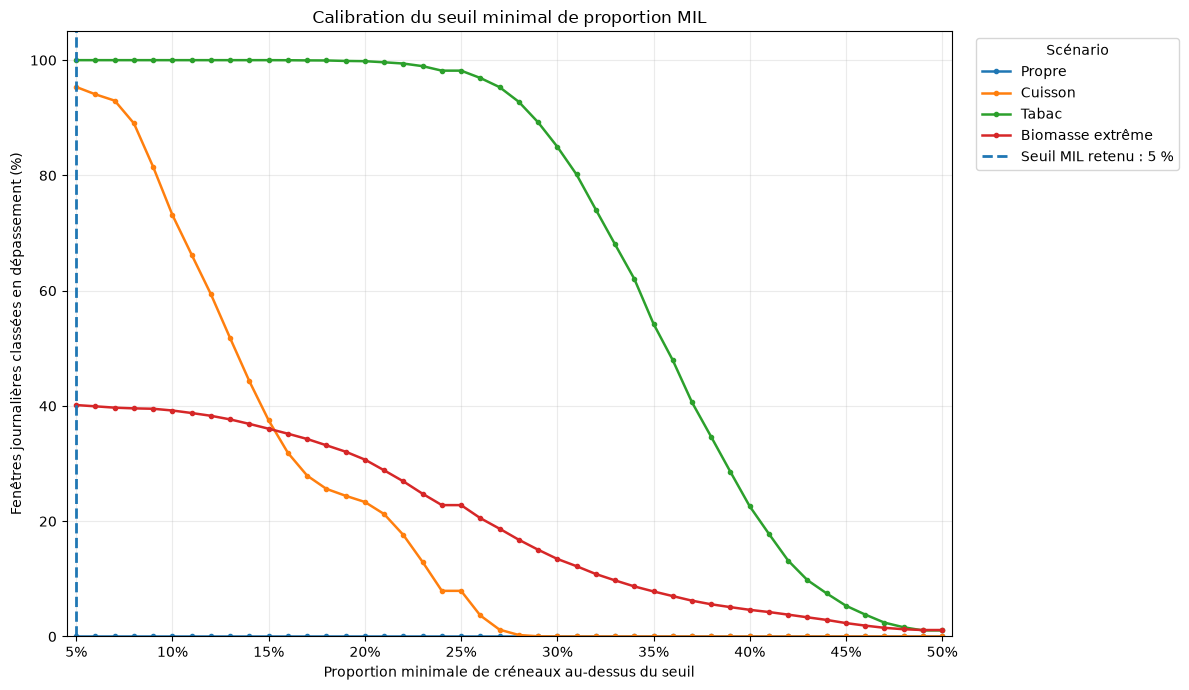

In [65]:
# Pour un seuil MIL alpha :
#
# dépassement MIL =
# proportion_above_threshold >= alpha
#
# proportion_above_threshold représente la proportion
# des créneaux de 15 minutes au-dessus du seuil PM2.5.

tested_mil_thresholds = np.round(
    np.arange(0.05, 0.501, 0.01),
    2,
)

calibration_rows = []

for scenario in scenario_order:

    scenario_data = data[
        data["emission_scenario"].eq(scenario)
    ]

    proportions = scenario_data[
        "proportion_above_threshold"
    ].to_numpy()

    for mil_threshold in tested_mil_thresholds:

        exceedance_rate = (
            proportions >= mil_threshold
        ).mean() * 100

        calibration_rows.append(
            {
                "emission_scenario": scenario,
                "mil_threshold": mil_threshold,
                "exceedance_rate": exceedance_rate,
            }
        )

calibration = pd.DataFrame(calibration_rows)

calibration.to_csv(
    OUTPUT_DIR_DETECT / "5_4_calibration_seuil_mil.csv",
    index=False,
)

fig, ax = plt.subplots(figsize=(12, 7))

for scenario in scenario_order:

    scenario_calibration = calibration[
        calibration["emission_scenario"].eq(
            scenario
        )
    ]

    ax.plot(
        scenario_calibration["mil_threshold"],
        scenario_calibration["exceedance_rate"],
        marker="o",
        markersize=3,
        linewidth=1.8,
        label=SCENARIO_LABELS.get(
            scenario,
            scenario,
        ),
    )

RETAINED_MIL_THRESHOLD = 0.05

ax.axvline(
    RETAINED_MIL_THRESHOLD,
    linestyle="--",
    linewidth=2,
    label="Seuil MIL retenu : 5 %",
)

ax.set_title(
    "Calibration du seuil minimal de proportion MIL"
)
ax.set_xlabel(
    "Proportion minimale de créneaux au-dessus du seuil"
)
ax.set_ylabel(
    "Fenêtres journalières classées en dépassement (%)"
)

mil_ticks = np.arange(
    0.05,
    0.51,
    0.05,
)

ax.set_xticks(mil_ticks)
ax.set_xticklabels(
    [
        f"{value:.0%}"
        for value in mil_ticks
    ]
)

ax.set_xlim(0.045, 0.505)
ax.set_ylim(0, 105)

ax.legend(
    title="Scénario",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
)

ax.grid(alpha=0.25)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR_DETECT / "5_4_calibration_seuil_mil.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

## Trajectoire longitudinale

In [67]:
TRAJECTORY_FILE = Path("./outputs/exposure_trajectory.csv.gz")

OUTPUT_DIR_TRA = Path("./figures/visualisations_trajectoires_longitudinales")
OUTPUT_DIR_TRA.mkdir(exist_ok=True)

POLLUTANT = "PM25"
PERSONA_ORDER = ["P1", "P2", "P3", "P4", "P5"]

# Tolérance maximale initiale pour considérer que deux
# moyennes annuelles sont comparables.
MEAN_SIMILARITY_TOLERANCES = [0.01, 0.02, 0.05, 0.10]

In [68]:
trajectory = pd.read_csv(TRAJECTORY_FILE)

required_columns = {
    "individual_id",
    "pollutant",
    "window_type",
    "window_start",
    "window_index",
    "cumulative_exposure",
    "consecutive_exceedances",
    "max_consecutive_exceedances_to_date",
}

missing_columns = required_columns.difference(
    trajectory.columns
)

if missing_columns:
    raise ValueError(
        "Colonnes manquantes dans exposure_trajectory : "
        + ", ".join(sorted(missing_columns))
    )

trajectory["window_start"] = pd.to_datetime(
    trajectory["window_start"],
    errors="coerce",
)

numeric_columns = [
    "window_index",
    "cumulative_exposure",
    "consecutive_exceedances",
    "max_consecutive_exceedances_to_date",
]

for column in numeric_columns:
    trajectory[column] = pd.to_numeric(
        trajectory[column],
        errors="coerce",
    )

trajectory = trajectory.dropna(
    subset=[
        "individual_id",
        "pollutant",
        "window_type",
        "window_start",
        "cumulative_exposure",
        "consecutive_exceedances",
        "max_consecutive_exceedances_to_date",
    ]
)

# P1_01 devient P1, P4_06 devient P4, etc.
trajectory["persona_id"] = (
    trajectory["individual_id"]
    .astype(str)
    .str.extract(r"^(P\d+)", expand=False)
)

if trajectory["persona_id"].isna().any():
    invalid_ids = (
        trajectory.loc[
            trajectory["persona_id"].isna(),
            "individual_id",
        ]
        .drop_duplicates()
        .astype(str)
        .tolist()
    )

    raise ValueError(
        "Impossible de déduire le persona pour : "
        + ", ".join(invalid_ids)
    )


In [69]:
daily = (
    trajectory[
        trajectory["pollutant"].eq(POLLUTANT)
        & trajectory["window_type"].eq("daily")
    ]
    .copy()
    .sort_values(
        ["individual_id", "window_start"]
    )
)

if daily.empty:
    raise ValueError(
        f"Aucune trajectoire journalière {POLLUTANT}."
    )

daily["year"] = daily["window_start"].dt.year
daily["day_of_year"] = (
    daily["window_start"].dt.dayofyear
)

# L'exposition journalière est obtenue par différence
# entre deux valeurs successives du cumul.
daily["daily_exposure"] = (
    daily
    .groupby("individual_id")[
        "cumulative_exposure"
    ]
    .diff()
)

first_observation = (
    daily
    .groupby("individual_id")
    .cumcount()
    .eq(0)
)

daily.loc[
    first_observation,
    "daily_exposure",
] = daily.loc[
    first_observation,
    "cumulative_exposure",
]

# Vérification du caractère cumulatif.
negative_increments = (
    daily["daily_exposure"] < -1e-8
)

if negative_increments.any():
    raise ValueError(
        "La variable cumulative_exposure diminue pour "
        "certaines observations. Vérifier sa définition."
    )

daily["daily_exposure"] = (
    daily["daily_exposure"].clip(lower=0)
)


Individus représentatifs pour la figure 6.1 :
persona_id individual_id  final_cumulative_exposure
        P1         P1_01               3.734647e+05
        P2         P2_01               3.266072e+05
        P3         P3_03               1.388071e+06
        P4         P4_06               1.917483e+06
        P5         P5_06               1.402144e+06


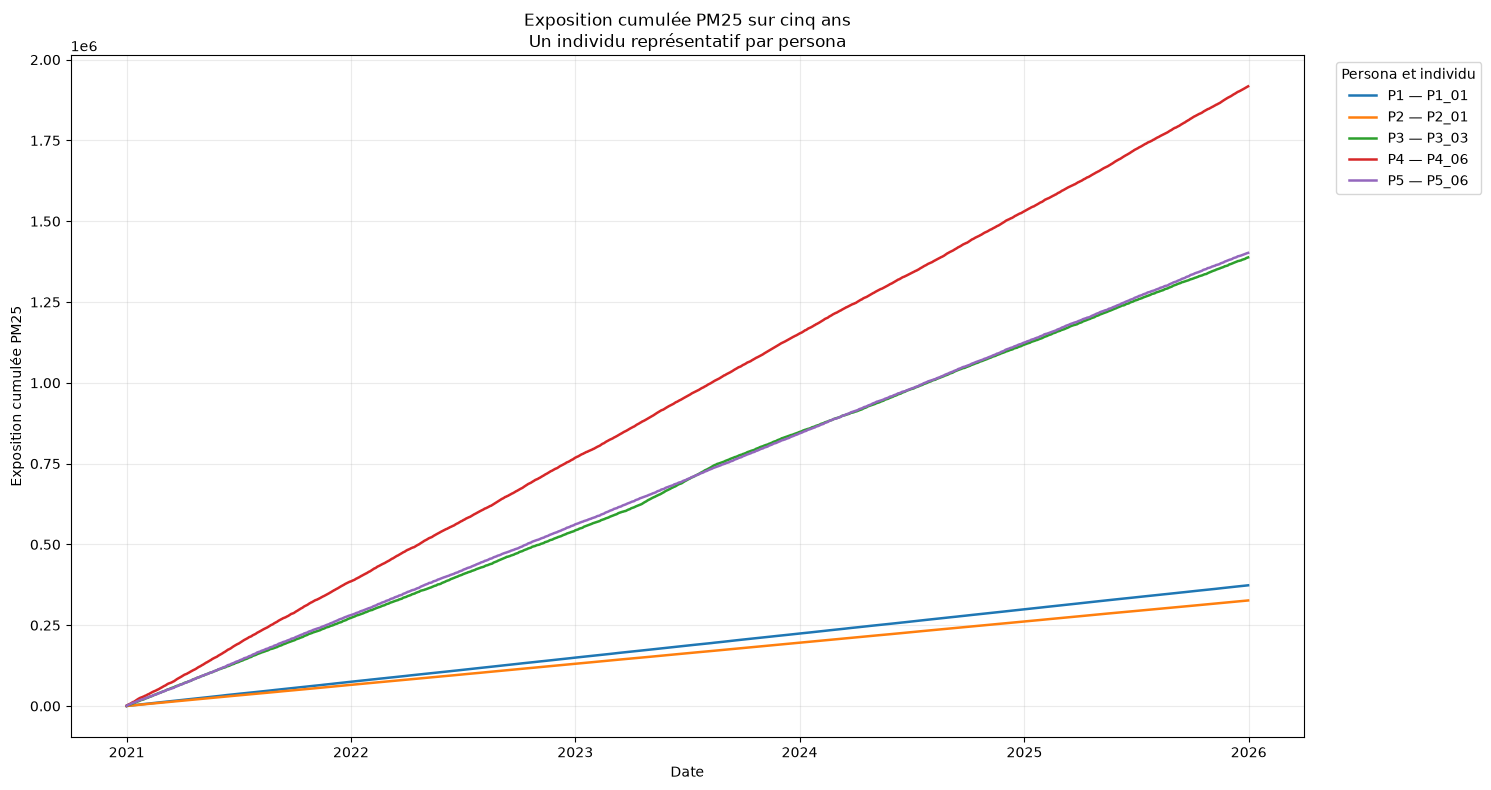

In [70]:
final_exposure = (
    daily
    .groupby(
        ["persona_id", "individual_id"],
        as_index=False,
    )
    .agg(
        final_cumulative_exposure=(
            "cumulative_exposure",
            "last",
        )
    )
)

final_exposure["persona_median"] = (
    final_exposure
    .groupby("persona_id")[
        "final_cumulative_exposure"
    ]
    .transform("median")
)

final_exposure["distance_to_median"] = (
    final_exposure[
        "final_cumulative_exposure"
    ]
    - final_exposure["persona_median"]
).abs()

representatives = (
    final_exposure
    .sort_values(
        [
            "persona_id",
            "distance_to_median",
            "individual_id",
        ]
    )
    .drop_duplicates("persona_id")
)

representative_map = dict(
    zip(
        representatives["persona_id"],
        representatives["individual_id"],
    )
)

print("\nIndividus représentatifs pour la figure 6.1 :")

print(
    representatives[
        [
            "persona_id",
            "individual_id",
            "final_cumulative_exposure",
        ]
    ].to_string(index=False)
)


fig, ax = plt.subplots(figsize=(15, 8))

for persona in PERSONA_ORDER:

    individual_id = representative_map.get(persona)

    if individual_id is None:
        continue

    individual_data = daily[
        daily["individual_id"].eq(individual_id)
    ]

    ax.plot(
        individual_data["window_start"],
        individual_data["cumulative_exposure"],
        linewidth=1.8,
        label=f"{persona} — {individual_id}",
    )

ax.set_title(
    f"Exposition cumulée {POLLUTANT} sur cinq ans\n"
    "Un individu représentatif par persona"
)

ax.set_xlabel("Date")
ax.set_ylabel(
    f"Exposition cumulée {POLLUTANT}"
)

ax.xaxis.set_major_locator(
    mdates.YearLocator()
)

ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%Y")
)

ax.grid(alpha=0.25)

ax.legend(
    title="Persona et individu",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR_TRA / "6_1_exposition_cumulee_5_ans.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()


Épisode sélectionné pour la figure 6.2 :
Individu : P4_02
Persona : P4
Début : 04/02/2021
Fin : 28/12/2021
Durée : 328 jours
Record précédent : 33 jours


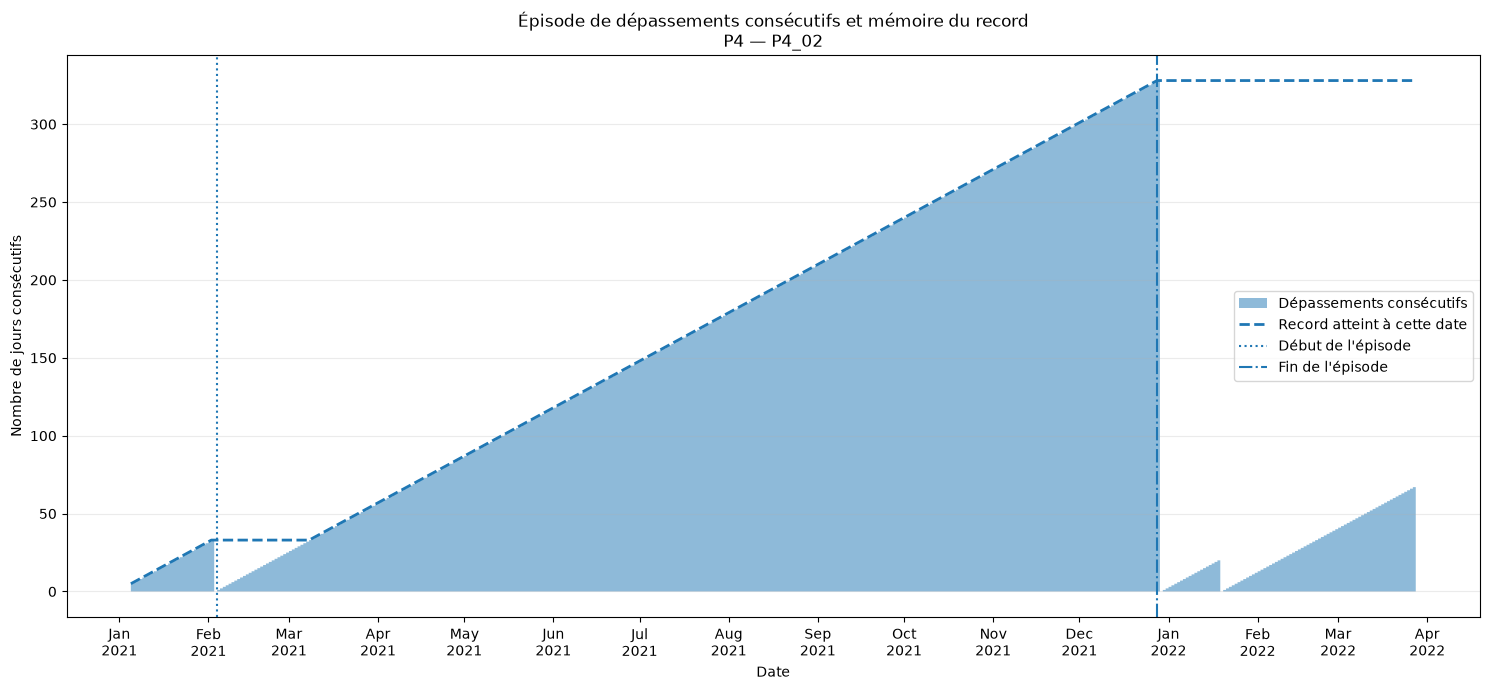

In [71]:
episode_candidates = []

for individual_id, individual_data in daily.groupby(
    "individual_id"
):

    individual_data = (
        individual_data
        .sort_values("window_start")
        .reset_index(drop=True)
    )

    next_consecutive = (
        individual_data[
            "consecutive_exceedances"
        ]
        .shift(-1)
    )

    completed_episode_ends = (
        individual_data[
            "consecutive_exceedances"
        ].gt(0)
        & next_consecutive.eq(0)
    )

    episode_end_rows = individual_data[
        completed_episode_ends
    ]

    for episode_end_row in episode_end_rows.itertuples():

        episode_length = int(
            episode_end_row.consecutive_exceedances
        )

        episode_end = episode_end_row.window_start

        episode_start = (
            episode_end
            - pd.Timedelta(
                days=episode_length - 1
            )
        )

        observations_before_episode = (
            individual_data[
                individual_data["window_start"]
                < episode_start
            ]
        )

        if observations_before_episode.empty:
            previous_record = 0
        else:
            previous_record = int(
                observations_before_episode[
                    "max_consecutive_exceedances_to_date"
                ].max()
            )

        # On privilégie un épisode qui établit un nouveau record.
        establishes_new_record = (
            episode_length > previous_record
        )

        episode_candidates.append(
            {
                "individual_id": individual_id,
                "persona_id": (
                    episode_end_row.persona_id
                ),
                "episode_start": episode_start,
                "episode_end": episode_end,
                "episode_length": episode_length,
                "previous_record": previous_record,
                "establishes_new_record": (
                    establishes_new_record
                ),
                "final_cumulative_exposure": (
                    individual_data[
                        "cumulative_exposure"
                    ].iloc[-1]
                ),
            }
        )

episodes = pd.DataFrame(episode_candidates)

if episodes.empty:
    raise ValueError(
        "Aucun épisode terminé de dépassements "
        "consécutifs n'a été trouvé."
    )

# Priorité :
# 1. épisode établissant un record ;
# 2. épisode le plus long ;
# 3. individu ayant le cumul final le plus élevé.
record_episodes = episodes[
    episodes["establishes_new_record"]
]

if record_episodes.empty:
    record_episodes = episodes

selected_episode = (
    record_episodes
    .sort_values(
        [
            "episode_length",
            "final_cumulative_exposure",
        ],
        ascending=[False, False],
    )
    .iloc[0]
)

selected_individual = (
    selected_episode["individual_id"]
)

episode_start = selected_episode["episode_start"]
episode_end = selected_episode["episode_end"]

# Ajout d'une période avant et après l'épisode pour montrer :
# - la montée du compteur ;
# - le retour à zéro ;
# - le maintien du record.
plot_start = (
    episode_start - pd.Timedelta(days=30)
)

plot_end = (
    episode_end + pd.Timedelta(days=90)
)

episode_data = daily[
    daily["individual_id"].eq(
        selected_individual
    )
    & daily["window_start"].between(
        plot_start,
        plot_end,
    )
].copy()

print("\nÉpisode sélectionné pour la figure 6.2 :")

print(
    f"Individu : {selected_individual}\n"
    f"Persona : {selected_episode['persona_id']}\n"
    f"Début : {episode_start:%d/%m/%Y}\n"
    f"Fin : {episode_end:%d/%m/%Y}\n"
    f"Durée : {selected_episode['episode_length']} jours\n"
    f"Record précédent : "
    f"{selected_episode['previous_record']} jours"
)


fig, ax = plt.subplots(figsize=(15, 7))

ax.fill_between(
    episode_data["window_start"],
    0,
    episode_data["consecutive_exceedances"],
    step="post",
    alpha=0.5,
    label="Dépassements consécutifs",
)

ax.plot(
    episode_data["window_start"],
    episode_data[
        "max_consecutive_exceedances_to_date"
    ],
    linestyle="--",
    linewidth=2,
    label="Record atteint à cette date",
)

ax.axvline(
    episode_start,
    linestyle=":",
    linewidth=1.5,
    label="Début de l'épisode",
)

ax.axvline(
    episode_end,
    linestyle="-.",
    linewidth=1.5,
    label="Fin de l'épisode",
)

ax.set_title(
    "Épisode de dépassements consécutifs et mémoire du record\n"
    f"{selected_episode['persona_id']} — "
    f"{selected_individual}"
)

ax.set_xlabel("Date")
ax.set_ylabel("Nombre de jours consécutifs")

ax.xaxis.set_major_locator(
    mdates.MonthLocator()
)

ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%b\n%Y")
)

ax.grid(axis="y", alpha=0.25)
ax.legend()

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR_TRA
    / (
        "6_2_depassements_consecutifs_"
        f"{selected_individual}.png"
    ),
    dpi=300,
    bbox_inches="tight",
)

plt.show()


In [73]:
# Statistiques individuelles par année.
annual_statistics = (
    daily
    .groupby(
        [
            "year",
            "persona_id",
            "individual_id",
        ],
        as_index=False,
    )
    .agg(
        mean_exposure=(
            "daily_exposure",
            "mean",
        ),
        exposure_sd=(
            "daily_exposure",
            "std",
        ),
        maximum_consecutive=(
            "consecutive_exceedances",
            "max",
        ),
        annual_total_exposure=(
            "daily_exposure",
            "sum",
        ),
    )
)

pair_candidates = []

for year, year_statistics in (
    annual_statistics.groupby("year")
):

    rows = list(
        year_statistics.itertuples(index=False)
    )

    for first, second in combinations(rows, 2):

        # On privilégie deux personas distincts.
        if first.persona_id == second.persona_id:
            continue

        average_of_means = (
            first.mean_exposure
            + second.mean_exposure
        ) / 2

        if average_of_means == 0:
            relative_mean_difference = 0
        else:
            relative_mean_difference = (
                abs(
                    first.mean_exposure
                    - second.mean_exposure
                )
                / average_of_means
            )

        first_daily = (
            daily[
                daily["individual_id"].eq(
                    first.individual_id
                )
                & daily["year"].eq(year)
            ]
            [
                [
                    "day_of_year",
                    "daily_exposure",
                    "consecutive_exceedances",
                ]
            ]
            .rename(
                columns={
                    "daily_exposure": (
                        "daily_exposure_first"
                    ),
                    "consecutive_exceedances": (
                        "consecutive_first"
                    ),
                }
            )
        )

        second_daily = (
            daily[
                daily["individual_id"].eq(
                    second.individual_id
                )
                & daily["year"].eq(year)
            ]
            [
                [
                    "day_of_year",
                    "daily_exposure",
                    "consecutive_exceedances",
                ]
            ]
            .rename(
                columns={
                    "daily_exposure": (
                        "daily_exposure_second"
                    ),
                    "consecutive_exceedances": (
                        "consecutive_second"
                    ),
                }
            )
        )

        aligned = first_daily.merge(
            second_daily,
            on="day_of_year",
            how="inner",
        )

        if len(aligned) < 300:
            continue

        aligned["cumulative_first"] = (
            aligned[
                "daily_exposure_first"
            ].cumsum()
        )

        aligned["cumulative_second"] = (
            aligned[
                "daily_exposure_second"
            ].cumsum()
        )

        first_total = (
            aligned["cumulative_first"].iloc[-1]
        )

        second_total = (
            aligned["cumulative_second"].iloc[-1]
        )

        if first_total <= 0 or second_total <= 0:
            continue

        # Les cumuls sont normalisés uniquement pour calculer
        # la différence de forme entre les trajectoires.
        normalized_first = (
            aligned["cumulative_first"]
            / first_total
        )

        normalized_second = (
            aligned["cumulative_second"]
            / second_total
        )

        trajectory_rmse = np.sqrt(
            np.mean(
                (
                    normalized_first
                    - normalized_second
                )
                ** 2
            )
        )

        consecutive_difference = abs(
            first.maximum_consecutive
            - second.maximum_consecutive
        )

        variability_difference = abs(
            first.exposure_sd
            - second.exposure_sd
        )

        pair_candidates.append(
            {
                "year": year,
                "individual_1": (
                    first.individual_id
                ),
                "persona_1": first.persona_id,
                "mean_1": first.mean_exposure,
                "sd_1": first.exposure_sd,
                "max_consecutive_1": (
                    first.maximum_consecutive
                ),
                "individual_2": (
                    second.individual_id
                ),
                "persona_2": second.persona_id,
                "mean_2": second.mean_exposure,
                "sd_2": second.exposure_sd,
                "max_consecutive_2": (
                    second.maximum_consecutive
                ),
                "relative_mean_difference": (
                    relative_mean_difference
                ),
                "trajectory_rmse": (
                    trajectory_rmse
                ),
                "consecutive_difference": (
                    consecutive_difference
                ),
                "variability_difference": (
                    variability_difference
                ),
            }
        )

pairs = pd.DataFrame(pair_candidates)

if pairs.empty:
    raise ValueError(
        "Aucune paire annuelle comparable trouvée."
    )

# Recherche avec une tolérance progressivement élargie.
similar_pairs = pd.DataFrame()

for tolerance in MEAN_SIMILARITY_TOLERANCES:

    similar_pairs = pairs[
        pairs["relative_mean_difference"]
        <= tolerance
    ].copy()

    if not similar_pairs.empty:
        selected_tolerance = tolerance
        break

if similar_pairs.empty:
    # Solution de secours : les 20 paires aux moyennes
    # les plus proches.
    similar_pairs = (
        pairs
        .nsmallest(
            20,
            "relative_mean_difference",
        )
        .copy()
    )

    selected_tolerance = (
        similar_pairs[
            "relative_mean_difference"
        ].max()
    )

# Score privilégiant :
# - une grande différence de répétition ;
# - une grande différence de forme du cumul ;
# - une grande différence de variabilité.
similar_pairs["consecutive_rank"] = (
    similar_pairs["consecutive_difference"]
    .rank(pct=True)
)

similar_pairs["trajectory_rank"] = (
    similar_pairs["trajectory_rmse"]
    .rank(pct=True)
)

similar_pairs["variability_rank"] = (
    similar_pairs["variability_difference"]
    .rank(pct=True)
)

similar_pairs["scientific_contrast_score"] = (
    0.45
    * similar_pairs["consecutive_rank"]
    + 0.40
    * similar_pairs["trajectory_rank"]
    + 0.15
    * similar_pairs["variability_rank"]
)

selected_pair = (
    similar_pairs
    .sort_values(
        [
            "scientific_contrast_score",
            "relative_mean_difference",
        ],
        ascending=[False, True],
    )
    .iloc[0]
)

comparison_year = int(
    selected_pair["year"]
)

individual_1 = selected_pair["individual_1"]
individual_2 = selected_pair["individual_2"]

comparison_data = daily[
    daily["year"].eq(comparison_year)
    & daily["individual_id"].isin(
        [individual_1, individual_2]
    )
].copy()

# Cumul propre à l'année, commençant à zéro.
comparison_data[
    "annual_cumulative_exposure"
] = (
    comparison_data
    .groupby("individual_id")[
        "daily_exposure"
    ]
    .cumsum()
)

print("\nPaire sélectionnée pour la figure 6.3 :")

print(
    f"Année : {comparison_year}\n"
    f"{selected_pair['persona_1']} — {individual_1} : "
    f"moyenne = {selected_pair['mean_1']:.2f}, "
    f"maximum consécutif = "
    f"{selected_pair['max_consecutive_1']:.0f} jours\n"
    f"{selected_pair['persona_2']} — {individual_2} : "
    f"moyenne = {selected_pair['mean_2']:.2f}, "
    f"maximum consécutif = "
    f"{selected_pair['max_consecutive_2']:.0f} jours\n"
    f"Écart relatif entre les moyennes : "
    f"{selected_pair['relative_mean_difference']:.2%}\n"
    f"Tolérance utilisée : {selected_tolerance:.0%}"
)


Paire sélectionnée pour la figure 6.3 :
Année : 2022
P2 — P2_06 : moyenne = 1050.40, maximum consécutif = 45 jours
P4 — P4_06 : moyenne = 1047.41, maximum consécutif = 116 jours
Écart relatif entre les moyennes : 0.29%
Tolérance utilisée : 1%


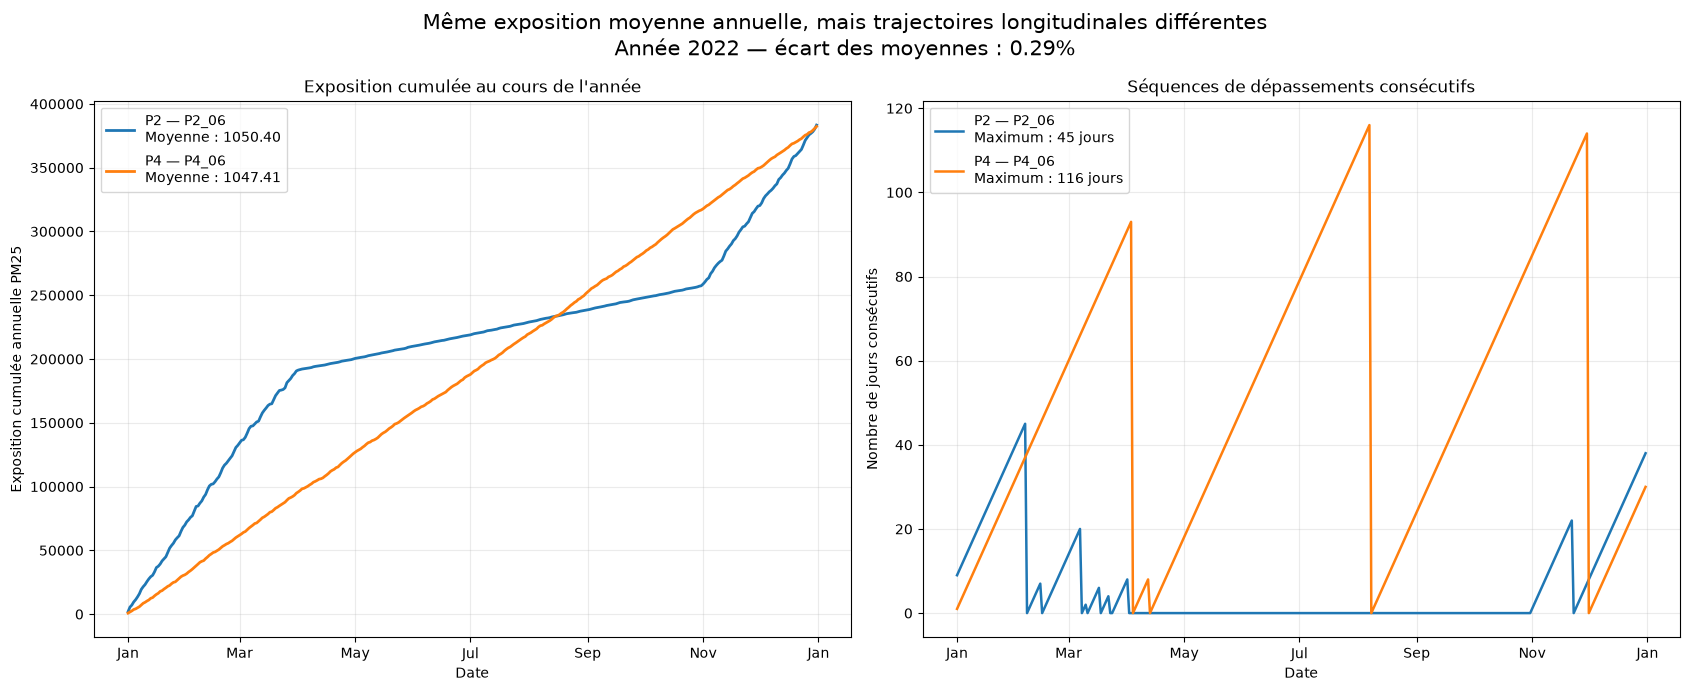

In [74]:
fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(17, 7),
)

# Graphique de gauche : cumul annuel
for individual_id, individual_data in (
    comparison_data.groupby("individual_id")
):

    persona = (
        individual_data["persona_id"].iloc[0]
    )

    mean_value = (
        individual_data["daily_exposure"].mean()
    )

    axes[0].plot(
        individual_data["window_start"],
        individual_data[
            "annual_cumulative_exposure"
        ],
        linewidth=2,
        label=(
            f"{persona} — {individual_id}\n"
            f"Moyenne : {mean_value:.2f}"
        ),
    )

axes[0].set_title(
    "Exposition cumulée au cours de l'année"
)

axes[0].set_xlabel("Date")
axes[0].set_ylabel(
    f"Exposition cumulée annuelle {POLLUTANT}"
)

axes[0].xaxis.set_major_locator(
    mdates.MonthLocator(interval=2)
)

axes[0].xaxis.set_major_formatter(
    mdates.DateFormatter("%b")
)

axes[0].grid(alpha=0.25)
axes[0].legend()


# Graphique de droite : dépassements consécutifs
for individual_id, individual_data in (
    comparison_data.groupby("individual_id")
):

    persona = (
        individual_data["persona_id"].iloc[0]
    )

    maximum_consecutive = (
        individual_data[
            "consecutive_exceedances"
        ].max()
    )

    axes[1].plot(
        individual_data["window_start"],
        individual_data[
            "consecutive_exceedances"
        ],
        linewidth=1.8,
        label=(
            f"{persona} — {individual_id}\n"
            f"Maximum : "
            f"{maximum_consecutive:.0f} jours"
        ),
    )

axes[1].set_title(
    "Séquences de dépassements consécutifs"
)

axes[1].set_xlabel("Date")
axes[1].set_ylabel(
    "Nombre de jours consécutifs"
)

axes[1].xaxis.set_major_locator(
    mdates.MonthLocator(interval=2)
)

axes[1].xaxis.set_major_formatter(
    mdates.DateFormatter("%b")
)

axes[1].grid(alpha=0.25)
axes[1].legend()

fig.suptitle(
    "Même exposition moyenne annuelle, "
    "mais trajectoires longitudinales différentes\n"
    f"Année {comparison_year} — "
    f"écart des moyennes : "
    f"{selected_pair['relative_mean_difference']:.2%}",
    fontsize=15,
)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR_TRA
    / (
        "6_3_meme_moyenne_trajectoires_differentes_"
        f"{comparison_year}.png"
    ),
    dpi=300,
    bbox_inches="tight",
)

plt.show()

In [75]:
# ============================================================
# Sauvegarde des individus et épisodes sélectionnés
# ============================================================

representatives[
    [
        "persona_id",
        "individual_id",
        "final_cumulative_exposure",
    ]
].to_csv(
    OUTPUT_DIR_TRA
    / "6_1_individus_representatifs.csv",
    index=False,
)

pd.DataFrame(
    [selected_episode.to_dict()]
).to_csv(
    OUTPUT_DIR_TRA
    / "6_2_episode_selectionne.csv",
    index=False,
)

pd.DataFrame(
    [selected_pair.to_dict()]
).to_csv(
    OUTPUT_DIR_TRA
    / "6_3_paire_selectionnee.csv",
    index=False,
)

## Dataset final exposition-santé